In [1]:
!python -m spacy download es

⚠ As of spaCy v3.0, shortcuts like 'es' are deprecated. Please use the
full pipeline package name 'es_core_news_sm' instead.
     ---------------------------------------- 0.0/12.9 MB ? eta -:--:--
     - -------------------------------------- 0.5/12.9 MB 2.4 MB/s eta 0:00:06
     --- ------------------------------------ 1.0/12.9 MB 3.0 MB/s eta 0:00:04
     ----- ---------------------------------- 1.8/12.9 MB 3.1 MB/s eta 0:00:04
     -------- ------------------------------- 2.9/12.9 MB 3.7 MB/s eta 0:00:03
     ------------ --------------------------- 3.9/12.9 MB 4.0 MB/s eta 0:00:03
     ---------------- ----------------------- 5.2/12.9 MB 4.4 MB/s eta 0:00:02
     -------------------- ------------------- 6.6/12.9 MB 4.6 MB/s eta 0:00:02
     ------------------------ --------------- 7.9/12.9 MB 4.8 MB/s eta 0:00:02
     --------------------------- ------------ 8.9/12.9 MB 5.0 MB/s eta 0:00:01
     -------------------------------- ------- 10.5/12.9 MB 5.2 MB/s eta 0:00:01
     -------

In [2]:
!python -m spacy download es_core_news_sm

  Using cached es_core_news_sm-3.8.0-py3-none-any.whl (12.9 MB)
✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_sm')


# Clasificación de críticas de películas filmaffinity

¡Bienvenido! 🎬✨  
Este notebook te guía paso a paso en el fascinante mundo de la **clasificación de textos** usando **NLP (Procesamiento de Lenguaje Natural)** y **regresión logística**.  
¿El reto? Analizar opiniones de películas y predecir si son positivas o negativas. 🧐🔍

**¿Por qué NLP y regresión logística?**  
- NLP permite entender y transformar el lenguaje humano en datos que los algoritmos pueden procesar.  
- La regresión logística es un modelo sencillo pero poderoso para clasificar textos y descubrir patrones ocultos. 🚀

**¿Qué aprenderás?**  
1. Cargar y explorar datos reales de críticas de películas.  
2. Definir el objetivo (target) según la puntuación de cada reseña.  
3. Limpiar y normalizar textos para prepararlos para el análisis.  
4. Dividir los datos en entrenamiento y test para evaluar el rendimiento.  
5. Crear representaciones numéricas de los textos (Bag-of-Words).  
6. Entrenar modelos de clasificación y medir su precisión.  
7. Interpretar resultados y visualizar métricas clave. 📊
 
¿Listo para convertir palabras en conocimiento? 💡🤖

In [3]:
import pandas as pd
import numpy as np
import spacy
import re
from tqdm import tqdm
from wordcloud import WordCloud #Word visualization
import matplotlib.pyplot as plt #Plotting properties
import seaborn as sns #Plotting properties
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer #Data transformation
from sklearn.model_selection import train_test_split #Data testing
from sklearn.linear_model import LogisticRegression #Prediction Model
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, r2_score, roc_curve, roc_auc_score, precision_recall_curve, average_precision_score
from sklearn.preprocessing import LabelEncoder #Variable encoding and decoding for XGBoost
import re #Regular expressions
import nltk
from nltk import word_tokenize
from ftfy import fix_text
from unicodedata import normalize, combining
import statsmodels.api as sm
from statsmodels.genmod.generalized_linear_model import GLM

nltk.download('stopwords')
from nltk.corpus import stopwords

from spacy.lang.es.stop_words import STOP_WORDS as SPACY_STOP_WORDS

nlp = spacy.load("es_core_news_sm")

# Une stopwords de NLTK y spaCy
stop_words = set(stopwords.words("spanish")) | set(SPACY_STOP_WORDS)

_ACCENT_MAP = str.maketrans({
    "á":"a","é":"e","í":"i","ó":"o","ú":"u","ü":"u",
    "Á":"a","É":"e","Í":"i","Ó":"o","Ú":"u","Ü":"u"
})


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\lucho\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [4]:
def plot_sigmoid(beta0=0.0, beta1=1.0, x=None, x_min=-6, x_max=6, n=500, show_threshold=True):
    """
    Grafica p(x) = sigmoid(beta0 + beta1*x).
    - beta0: intercepto
    - beta1: coeficiente (pendiente)
    - x: vector opcional de x; si es None, se genera en [x_min, x_max] con n puntos
    - show_threshold: dibuja líneas de referencia en p=0.5 y en x*=-beta0/beta1 (si aplica)
    """
    if x is None:
        x = np.linspace(x_min, x_max, n)
    z = beta0 + beta1 * x
    p = 1.0 / (1.0 + np.exp(-z))

    plt.figure(figsize=(6, 4))
    plt.plot(x, p, label="sigmoid(beta0 + beta1·x)")
    if show_threshold:
        # línea horizontal p=0.5
        plt.axhline(0.5, linestyle="--")
        # frontera de decisión x* = -beta0/beta1 (si beta1 != 0)
        if beta1 != 0:
            x_star = -beta0 / beta1
            plt.axvline(x_star, linestyle="--", label=f"x* = {-beta0:.3f}/{beta1:.3f}")
    plt.xlabel("x")
    plt.ylabel("p(x)")
    plt.title("Curva logística (inversa del logit)")
    plt.ylim(-0.05, 1.05)
    plt.legend()
    plt.tight_layout()
    plt.show()


def plot_logit(p_min=1e-4, p_max=1-1e-4, n=500):
    """
    Grafica y = logit(p) = log(p/(1-p)) para p en (0,1).
    - p_min/p_max evitan valores 0 o 1 exactos (así no explota a ±∞)
    """
    p = np.linspace(p_min, p_max, n)
    y = np.log(p / (1 - p))

    plt.figure(figsize=(6, 4))
    plt.plot(p, y, label="logit(p) = ln(p/(1-p))")
    # asintotas en p=0 y p=1 (límites del dominio)
    plt.axvline(0.0, linestyle="--")
    plt.axvline(1.0, linestyle="--")
    plt.xlabel("p")
    plt.ylabel("logit(p)")
    plt.title("Función logit")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [5]:
def remove_stopwords(text):
    no_stopword_text = [w for w in text.split() if not w in stop_words]
    return ' '.join(no_stopword_text)

def to_lemmas_es(text: str, remove_stop: bool = True, strip_accents: bool = False) -> str:
    doc = nlp(str(text))
    lemmas = []
    for tok in doc:
        if not tok.is_alpha:
            continue
        lemma = tok.lemma_.lower()
        if remove_stop and lemma in stop_words:
            continue
        lemmas.append(lemma)
    out = " ".join(lemmas)
    if strip_accents:
        out = strip_accents_keep_enye(out)
    return out


def strip_accents_keep_enye(s: str) -> str:
    # Quita tildes conservando ñ/Ñ aunque venga como n + tilde combinante
    s = normalize("NFD", str(s))
    s = s.replace("n\u0303", "ñ").replace("N\u0303", "Ñ")
    s = "".join(ch for ch in s if not combining(ch))
    return normalize("NFC", s)

def clean_text_basic(text: str, strip_accents: bool = False) -> str:
    """
    Limpieza segura:
    - Arregla encoding
    - Mantiene letras españolas (áéíóúüñ y mayúsculas)
    - Reemplaza lo demás por espacio y colapsa espacios
    - Minúsculas
    - (Opcional) quita tildes PERO conserva ñ
    """
    text = fix_text(str(text))
    text = re.sub(r"[^A-Za-zÁÉÍÓÚÜÑáéíóúüñ\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip().lower()
    if strip_accents:
        text = strip_accents_keep_enye(text)
    return text


def clean_text(text):
    # remove backslash-apostrophe 
    char=[',','?','.','"','-','(',')','\'',' n ']
    for i in range(0,len(char)):
        text=text.replace(char[i],'')
    text = re.sub(r"([^n\u0300-\u036f]|n(?!\u0303(?![\u0300-\u036f])))[\u0300-\u036f]+", r"\1", 
        normalize( "NFD", text), 0, re.I
    )
    text = normalize( 'NFC', text)
    text = re.sub("\'", "", text) 
    # remove everything except alphabets 
    text = re.sub("[^a-zA-Z]"," ",text) 
    # remove whitespaces 
    text = ' '.join(text.split()) 
    # convert text to lowercase 
    text = text.lower() 
    
    return text


In [6]:
df = pd.read_table('reviews_filmaffinity.csv', sep='\|\|', header=0, engine='python')
df.sort_values(by='film_name').head(5)

,film_name,gender,film_avg_rate,review_rate,review_title,review_text
6962,Ahora o nunca,Comedia,"4,4",2.0,"Mírala ahora, si quieres perder el tiempo y nu...",Guión rebuscado. Todo es predecible menos los ...
6938,Ahora o nunca,Comedia,"4,4",2.0,Escoria,Partiendo de un título nada original nos adent...
6939,Ahora o nunca,Comedia,"4,4",1.0,Ahora o Nunca: Nueve apellidos vascos,"Mi abuela materna, que era una republicana con..."
6940,Ahora o nunca,Comedia,"4,4",5.0,Comedia para pasar el rato,"Una película muy básica, emulando grandes éxit..."
6941,Ahora o nunca,Comedia,"4,4",1.0,MALA NO.....LO SIGUIENTE.,Aburrida a más no poder.....plana en todos los...


In [7]:
df["film_name"].unique()

array(['Ocho apellidos vascos', 'Lo imposible',
       'Ocho apellidos catalanes', 'El orfanato',
       'La gran aventura de Mortadelo y Filemón',
       'Torrente 2: Misión en Marbella', 'Ágora',
       'Perfectos desconocidos', 'Mar adentro', 'Torrente 4', 'Campeones',
       'Las aventuras de Tadeo Jones', 'Torrente 3', 'Tadeo Jones 2',
       'Palmeras en la nieve', 'Alatriste', 'Celda 211', 'Superlópez',
       'El otro lado de la cama', 'Días de fútbol', 'Tengo ganas de ti',
       'Planet 51', 'Lo dejo cuando quiera', 'Atrapa la bandera',
       'Torrente, el brazo tonto de la ley', 'Mientras dure la guerra',
       'Torrente 5', 'Perdiendo el norte', 'Volver',
       'Villaviciosa de al lado', 'Todo sobre mi madre',
       'Tres metros sobre el cielo', 'Es por tu bien',
       'La niña de tus ojos', 'Regresión', 'El laberinto del fauno',
       'Juana La Loca', 'Ahora o nunca', 'Los crímenes de Oxford', 'REC',
       'AirBag', 'Las 13 rosas', 'El bola', 'El mejor verano de mi 

In [8]:
row = df.sort_values(by='film_name')[(df.sort_values(by='film_name')["review_rate"]==10)&(df.sort_values(by='film_name')["film_name"]=="Tres metros sobre el cielo")].iloc[0]
for col in df.columns:
    print(f"{col}: {row[col]}")

film_name: Tres metros sobre el cielo
gender: Romance
film_avg_rate: 4,7
review_rate: 10.0
review_title: Mi Película favorita
review_text: Definitivamente esta película merece un 10.Tres Metros Sobre el Cielo es una pelicula juvenil española muy bien realizada, con unos paisajes hermosos,unos personajes que trasmiten todo lo que estan viviendo con unas grandes actuaciones.La banda sonora de la Película es acorde a la historia y todas y cada una de las canciones me encantan.La historia de Babi y H es Preciosa y creible gracias a la excelente Quimica entre sus protagonistas Mario Casas y Maria Valverde.Unos secundarios muy bien aprovechados y es que en esta película todos los personajes aportan algo.Me gusto mucho como se desarrollo la historia entre Katina y Pollo que a pesar de ser personajes secundarios logran que su historia de amor enganche tanto como la de los Protagonistas.Lo mejor de la película: Las actuaciones de Mario Casas, María Valverde, Álvaro Cervantes y Marina Salas.


In [9]:
row = df.sort_values(by='film_name')[(df.sort_values(by='film_name')["review_rate"]==1)&(df.sort_values(by='film_name')["film_name"]=="Tres metros sobre el cielo")].iloc[0]
for col in df.columns:
    print(f"{col}: {row[col]}")

film_name: Tres metros sobre el cielo
gender: Romance
film_avg_rate: 4,7
review_rate: 1.0
review_title: Lo peor que he visto en mi vida.
review_text: La tuve que ver a la fuerza por mi novia y pase un mal rato en el cine.No había visto una película más estúpida en mi vida. El chico malote que pega palizas y parece se justifican, las vergonzosas carreras de motos, y un sin fin de incongruencias morales.En definitiva la peor historia llevada al cine.


In [10]:
avg_review_rate = df.groupby("film_name")["review_rate"].mean()
avg_review_rate.sort_values(ascending=False)

film_name
El bola                                    7.515625
Celda 211                                  7.285421
El laberinto del fauno                     7.242424
Mientras dure la guerra                    6.870647
La isla mínima                             6.863962
Mar adentro                                6.851163
Campeones                                  6.834171
Volver                                     6.830258
La niña de tus ojos                        6.742857
Tadeo Jones 2                              6.472222
Perfectos desconocidos                     6.382883
Ágora                                      6.366397
Todo sobre mi madre                        6.286822
Lo imposible                               6.278723
REC                                        6.262626
Torrente, el brazo tonto de la ley         6.196850
Las 13 rosas                               6.157143
El orfanato                                6.154709
Días de fútbol                             5.947368
Ju

In [11]:
df['polaridad'] = df['review_rate'].apply(lambda  x: 'positivo' if x > 6
                                          else 'negativo-neutro')

                                        #   else ('negativo' if x < 4
                                        #         else 'neutro'))
df.head()

,film_name,gender,film_avg_rate,review_rate,review_title,review_text,polaridad
0,Ocho apellidos vascos,Comedia,"6,0",3.0,OCHO APELLIDOS VASCOS...Y NINGÚN NOMBRE PROPIO,La mayor virtud de esta película es su existen...,negativo-neutro
1,Ocho apellidos vascos,Comedia,"6,0",2.0,El perro verde,"No soy un experto cinéfilo, pero pocas veces m...",negativo-neutro
2,Ocho apellidos vascos,Comedia,"6,0",2.0,Si no eres de comer mierda... no te comas esta...,Si no eres un incondicional del humor estilo T...,negativo-neutro
3,Ocho apellidos vascos,Comedia,"6,0",2.0,Aida: The movie,"No sé qué está pasando, si la gente se deja ll...",negativo-neutro
4,Ocho apellidos vascos,Comedia,"6,0",2.0,UN HOMBRE SOLO (Julio Iglesias 1987),"""Pero cuando amanece,y me quedo solo,siento en...",negativo-neutro


Text(30.764506172839504, 0.5, 'Nº Votos')

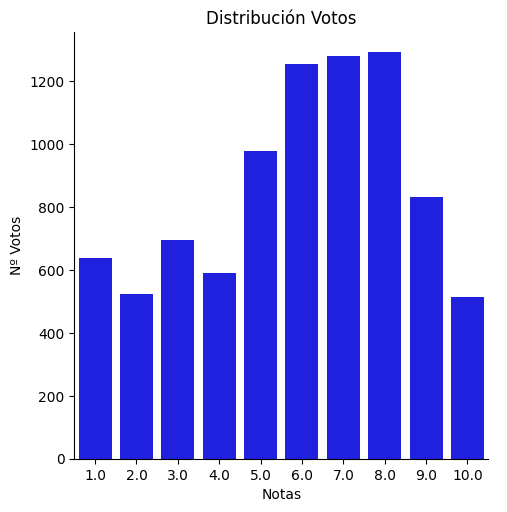

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns


sns.catplot(x='review_rate', kind='count', color='b', data=df)
plt.title('Distribución Votos')
plt.xlabel('Notas')
plt.ylabel('Nº Votos')

Text(30.764506172839504, 0.5, 'Nº Votos')

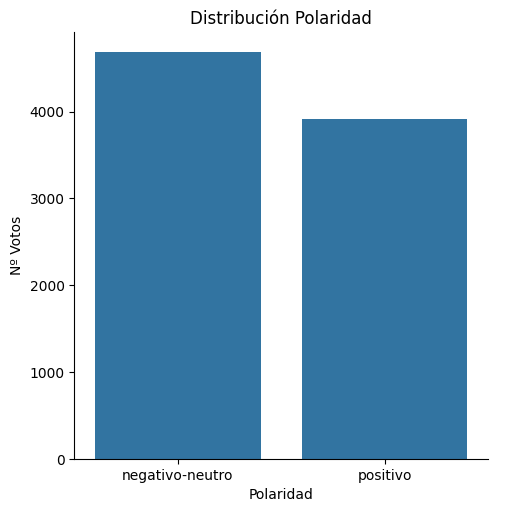

In [13]:
sns.catplot(x='polaridad', kind='count', data=df,  order=['negativo-neutro', 'positivo'])
plt.title('Distribución Polaridad')
plt.xlabel('Polaridad')
plt.ylabel('Nº Votos')

In [14]:
df['polaridad'].value_counts(normalize=True)

polaridad
negativo-neutro    0.544345
positivo           0.455655
Name: proportion, dtype: float64

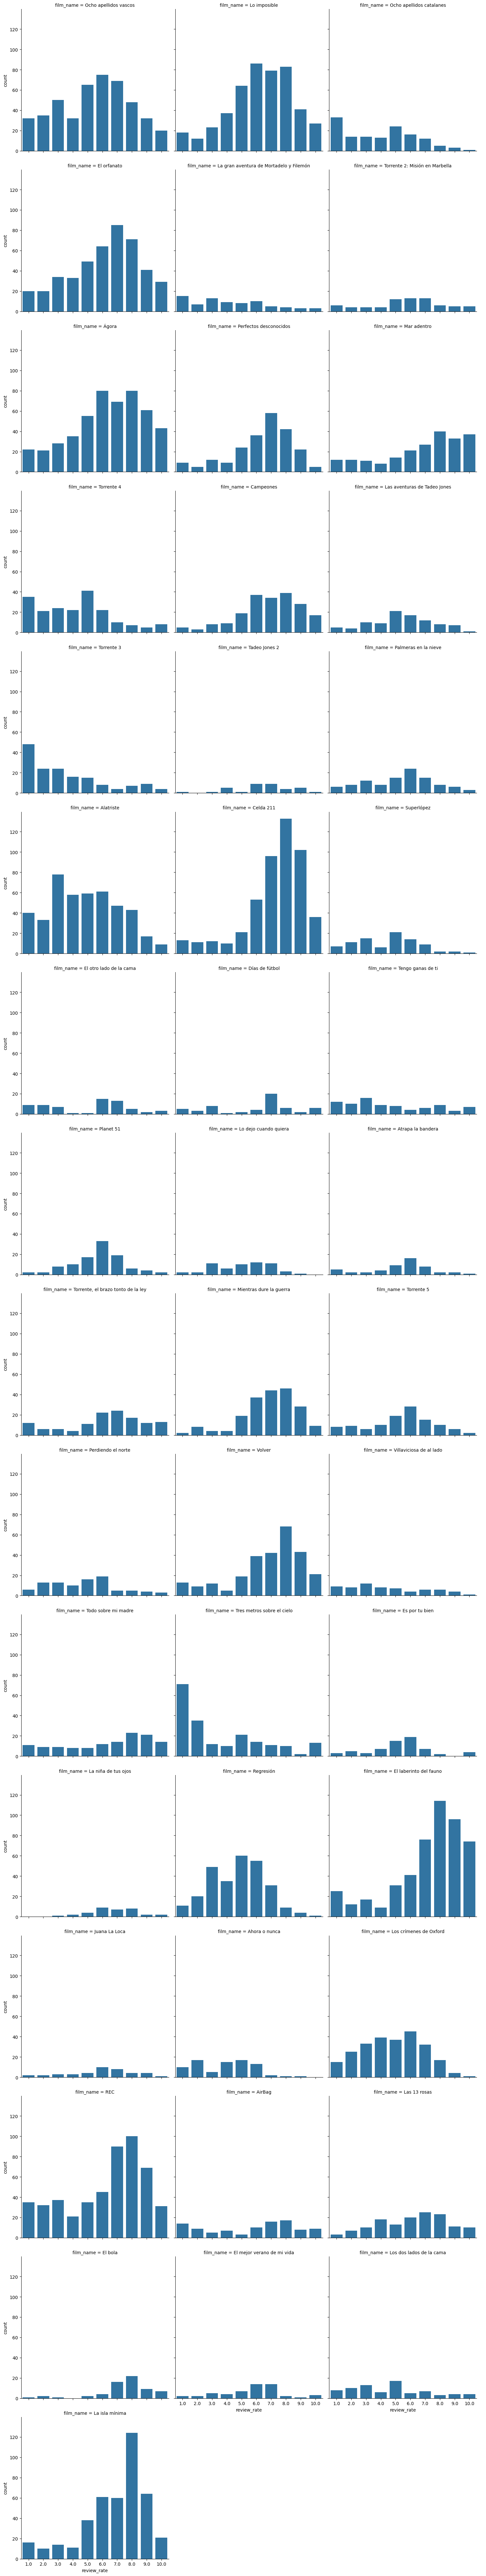

In [15]:
sns.catplot(x="review_rate", col="film_name", data=df, kind='count', col_wrap=3)

In [16]:
df["film_name"].nunique()

46

*********************
Polaridad: negativo-neutro
*********************


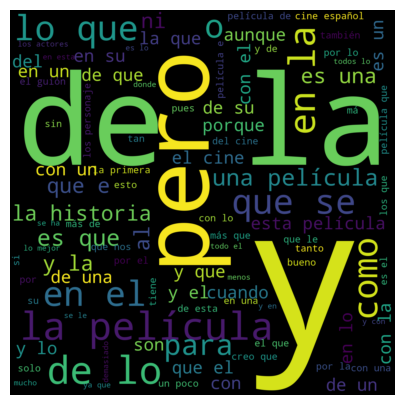

*********************
Polaridad: positivo
*********************


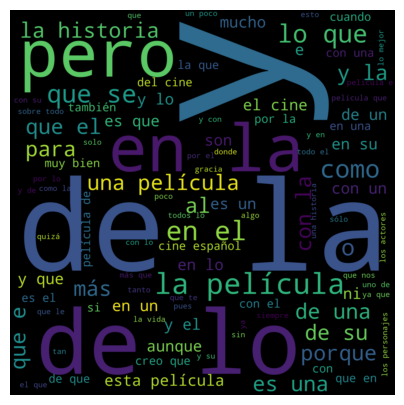

In [17]:
for vote in df["polaridad"].unique():
    print("*********************")
    print("Polaridad:", vote)
    print("*********************")
    word_cloud_text = ''.join(df[df["polaridad"]==vote].review_text.str.lower())
    #Creation of wordcloud
    wordcloud = WordCloud(
        max_font_size=100,
        max_words=100,
        background_color="black",
        scale=10,
        width=200,
        height=200
    ).generate(word_cloud_text)
    #Figure properties
    plt.figure(figsize=(5,5))
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.show()

In [18]:
df["review_text_norm"] = df["review_text"].apply(lambda x: clean_text_basic(x, strip_accents=False))
df["review_text_lemmas"] = df["review_text_norm"].apply(lambda x: to_lemmas_es(x, remove_stop=True, strip_accents=False))
df["review_text_lemmas_noacc"] = df["review_text_lemmas"].apply(strip_accents_keep_enye)
df.head()

,film_name,gender,film_avg_rate,review_rate,review_title,review_text,polaridad,review_text_norm,review_text_lemmas,review_text_lemmas_noacc
0,Ocho apellidos vascos,Comedia,"6,0",3.0,OCHO APELLIDOS VASCOS...Y NINGÚN NOMBRE PROPIO,La mayor virtud de esta película es su existen...,negativo-neutro,la mayor virtud de esta película es su existen...,virtud película existencia jugar tópico extrem...,virtud pelicula existencia jugar topico extrem...
1,Ocho apellidos vascos,Comedia,"6,0",2.0,El perro verde,"No soy un experto cinéfilo, pero pocas veces m...",negativo-neutro,no soy un experto cinéfilo pero pocas veces me...,experto cinéfilo sentir juego sala cine autént...,experto cinefilo sentir juego sala cine autent...
2,Ocho apellidos vascos,Comedia,"6,0",2.0,Si no eres de comer mierda... no te comas esta...,Si no eres un incondicional del humor estilo T...,negativo-neutro,si no eres un incondicional del humor estilo t...,incondicional humor estilo tele termina captar...,incondicional humor estilo tele termina captar...
3,Ocho apellidos vascos,Comedia,"6,0",2.0,Aida: The movie,"No sé qué está pasando, si la gente se deja ll...",negativo-neutro,no sé qué está pasando si la gente se deja lle...,pasar gente dejar moda gustar dani rovira éxit...,pasar gente dejar moda gustar dani rovira exit...
4,Ocho apellidos vascos,Comedia,"6,0",2.0,UN HOMBRE SOLO (Julio Iglesias 1987),"""Pero cuando amanece,y me quedo solo,siento en...",negativo-neutro,pero cuando amanece y me quedo solo siento en ...,amanecer quedo sentir fondoun mar vacío seco r...,amanecer quedo sentir fondoun mar vacio seco r...


*********************
Polaridad: negativo-neutro
*********************


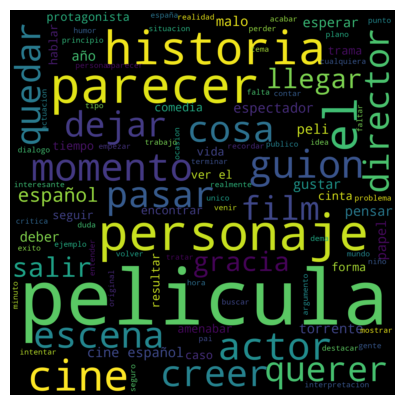

*********************
Polaridad: positivo
*********************


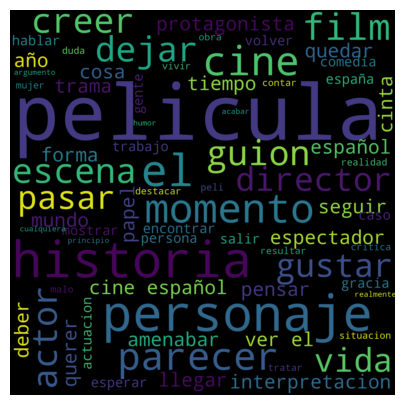

In [19]:
for vote in df["polaridad"].unique():
    print("*********************")
    print("Polaridad:", vote)
    print("*********************")
    word_cloud_text = ''.join(df[df["polaridad"]==vote].review_text_lemmas_noacc.str.lower())
    #Creation of wordcloud
    wordcloud = WordCloud(
        max_font_size=100,
        max_words=100,
        background_color="black",
        scale=10,
        width=200,
        height=200
    ).generate(word_cloud_text)
    #Figure properties
    plt.figure(figsize=(5,5))
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.show()

# Pre-Procesamiento del modelo

In [20]:
X = df["review_text_lemmas_noacc"]
y = df["polaridad"]

In [21]:
X

0       virtud pelicula existencia jugar topico extrem...
1       experto cinefilo sentir juego sala cine autent...
2       incondicional humor estilo tele termina captar...
3       pasar gente dejar moda gustar dani rovira exit...
4       amanecer quedo sentir fondoun mar vacio seco r...
                              ...                        
8598    film serio interpretacion estelar fotografia i...
8599    esperar guion visto novedoso absoluto previsib...
8600    cuerpo sensacion finalizar historia interesant...
8601    añadir comentario guion pesimo actuacion bland...
8602    pelicula cine entusiasmo prometer sesion hpero...
Name: review_text_lemmas_noacc, Length: 8603, dtype: object

In [22]:
X = df["review_text_lemmas_noacc"].astype(str)

# Tokenizar por espacios (ya son lemmas limpios)
tokens_text = X.str.split().tolist()

# Contar vocabulario único
tokens_counter = [tok for sent in tokens_text for tok in sent]
print("Number of tokens:", len(set(tokens_counter)))

# from sklearn.feature_extraction.text import CountVectorizer

# X = df["review_text_lemmas_noacc"].astype(str)

# # Usar split como tokenizer; desactiva token_pattern para evitar warnings
# cv = CountVectorizer(tokenizer=str.split, preprocessor=None, lowercase=False, token_pattern=None)
# X_mat = cv.fit_transform(X)
# print("Number of tokens:", len(cv.vocabulary_))

Number of tokens: 38916


In [23]:
tokens_text[0]

['virtud',
 'pelicula',
 'existencia',
 'jugar',
 'topico',
 'extremo',
 'identidad',
 'patrio',
 'andaluz',
 'vasca',
 'escandalizar',
 'grito',
 'cielo',
 'indicar',
 'madurez',
 'nacion',
 'pese',
 'pese',
 'corrijo',
 'jugar',
 'mofa',
 'befa',
 'topico',
 'vasco',
 'nacionalismo',
 'vasco',
 'escandalizar',
 'grito',
 'cielo',
 'indicar',
 'grado',
 'normalizacion',
 'cuestion',
 'llaga',
 'abierto',
 'dispuesto',
 'sangrar',
 'correccion',
 'andaluz',
 'motivo',
 'guasa',
 'pasar',
 'planteamiento',
 'apellido',
 'vasco',
 'valiente',
 'oportuno',
 'oportunista',
 'seguramente',
 'principal',
 'razon',
 'español',
 'acudir',
 'masa',
 'masa',
 'precedente',
 'cine',
 'producto',
 'patrocinado',
 'tele',
 'acertado',
 'fecha',
 'estreno',
 'oscar',
 'blockbuster',
 'verano',
 'brutal',
 'ejemplar',
 'campaña',
 'marketing',
 'aplaudo',
 'celebro',
 'celebrar',
 'desproposito',
 'repetir',
 'oscuro',
 'placer',
 'pelicula',
 'mala',
 'disfrutarla',
 'insistir',
 'olvidar',
 'princi

In [24]:
from sklearn.model_selection import train_test_split  

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

print('Textos de entrenamiento: {}'.format(len(X_train)))
print('Textos de test: {}'.format(len(X_test)))

Textos de entrenamiento: 6882
Textos de test: 1721


[]

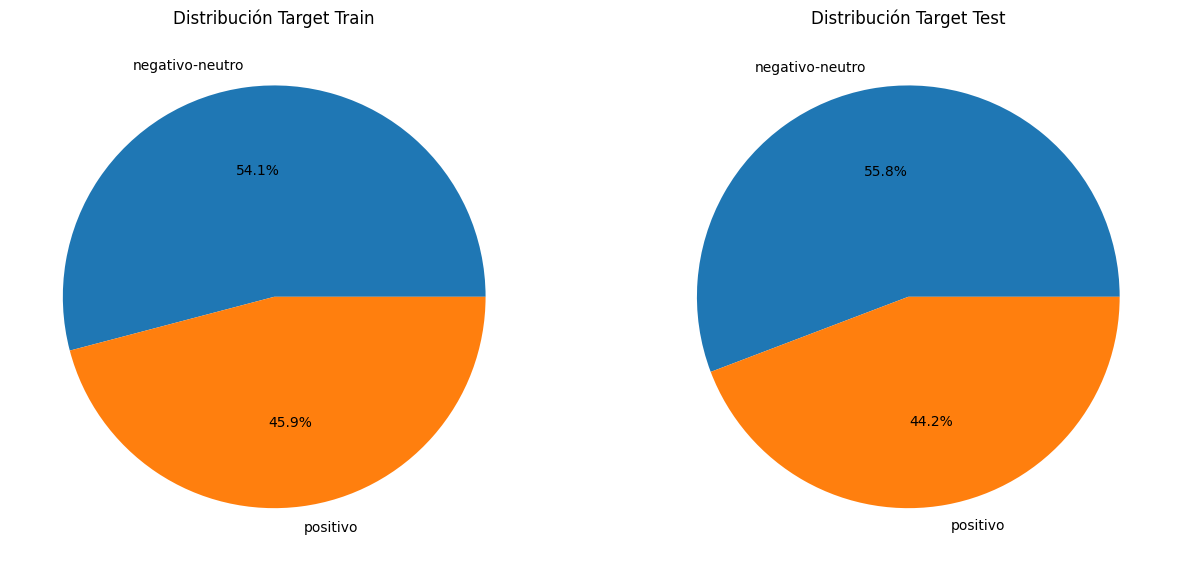

In [25]:
keys_train, counts_train = np.unique(y_train, return_counts=True)
keys_test, counts_test = np.unique(y_test, return_counts=True)
perct_train = counts_train / np.sum(counts_train)
perct_test = counts_test / np.sum(counts_test)

plt.figure(figsize=(15, 15))
plt.subplot(1, 2, 1)
plt.pie(perct_train, labels=keys_train, autopct='%1.1f%%')
plt.title('Distribución Target Train')
plt.subplot(1, 2, 2)
plt.pie(perct_test, labels=keys_test, autopct='%1.1f%%')
plt.title('Distribución Target Test')
plt.plot()

# 📚 N-gramas

Un N-Grama es una secuencia contigua de ‘N’ elementos extraída de un texto o discurso. En PLN, estos elementos suelen ser palabras o caracteres. Por ejemplo, en un bigrama ($N=2$), la secuencia consta de dos palabras consecutivas. Los N-Gramas son herramientas clave para modelar el lenguaje y analizar textos. 🧩

En PLN dentro de la IA, los N-Gramas se usan para desarrollar modelos de lenguaje que predicen la probabilidad de una secuencia de palabras. Son fundamentales en aplicaciones como traducción automática, reconocimiento de voz, generación de texto y chatbots. También ayudan en análisis de sentimientos y clasificación de texto, donde ciertos patrones pueden indicar opiniones o temas específicos. Al capturar frecuencias y patrones, permiten a los sistemas entender y manipular el lenguaje de forma más efectiva. 🚀

## ❓ ¿Cómo influye el tamaño de $N$ en la efectividad y precisión?

 - Unigramas ($N=1$): capturan menos contexto; simples y con menos combinaciones.
 - Bigramas ($N=2$) y Trigramas ($N=3$): capturan más contexto y mejoran la representación de la secuencia, aumentando la precisión.
 - $N$ grande: mayor especificidad y más datos requeridos, posible escasez y complejidad computacional.

👉 Hay que equilibrar el valor de $N$ según el objetivo y el tamaño del dataset.

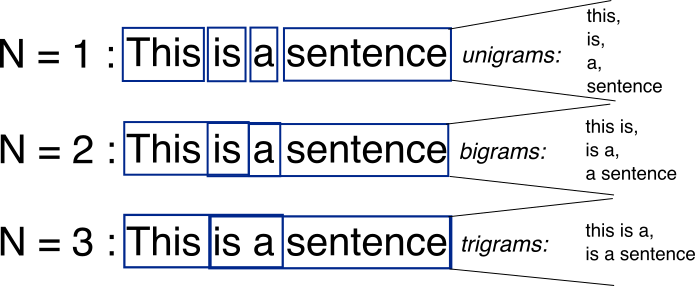


In [26]:
# Código ilustrativo de N-gramas
from sklearn.feature_extraction.text import CountVectorizer

docs = [
    "el gato come pescado",
    "el perro come carne",
    "gato y perro juegan"
]

# Extraer palabras distintas en docs
total_words = set()
for doc in docs:
    total_words.update(doc.split())
print("Palabras distintas:", total_words)

# N-gramas de palabras: unigrams
cv_word_ngrams = CountVectorizer(ngram_range=(1,1))
X = cv_word_ngrams.fit_transform(docs)
print("Vocabulario (palabras):", cv_word_ngrams.get_feature_names_out()[:20])
print("Shape:", X.shape)

# N-gramas de palabras: biigrams
cv_word_ngrams = CountVectorizer(ngram_range=(2,2))
X = cv_word_ngrams.fit_transform(docs)
print("Vocabulario (palabras):", cv_word_ngrams.get_feature_names_out()[:20])
print("Shape:", X.shape)


# N-gramas de palabras: unigrams + bigrams
cv_word_ngrams = CountVectorizer(ngram_range=(1,2))
X = cv_word_ngrams.fit_transform(docs)
print("Vocabulario (palabras):", cv_word_ngrams.get_feature_names_out()[:20])
print("Shape:", X.shape)

# N-gramas de caracteres (robustos a typos): 3 a 5
cv_char_ngrams = CountVectorizer(analyzer="char", ngram_range=(3,5))
Xc = cv_char_ngrams.fit_transform(docs)
print("Vocabulario (caracteres) tamaño:", len(cv_char_ngrams.get_feature_names_out()))
print("Shape:", Xc.shape)

Palabras distintas: {'y', 'carne', 'perro', 'pescado', 'gato', 'come', 'juegan', 'el'}
Vocabulario (palabras): ['carne' 'come' 'el' 'gato' 'juegan' 'perro' 'pescado']
Shape: (3, 7)
Vocabulario (palabras): ['come carne' 'come pescado' 'el gato' 'el perro' 'gato come' 'gato perro'
 'perro come' 'perro juegan']
Shape: (3, 8)
Vocabulario (palabras): ['carne' 'come' 'come carne' 'come pescado' 'el' 'el gato' 'el perro'
 'gato' 'gato come' 'gato perro' 'juegan' 'perro' 'perro come'
 'perro juegan' 'pescado']
Shape: (3, 15)
Vocabulario (caracteres) tamaño: 115
Shape: (3, 115)


# CountVectorizer

CountVectorizer (de scikit-learn) transforma documentos en una matriz de conteos (Bag-of-Words). Es una herramienta esencial en el preprocesamiento porque convierte texto → números que los modelos pueden usar. 💡

## 🧠 Intuición rápida

 - Columna → término del vocabulario.
 - Fila → documento.
 - Celda → frecuencia de ese término en el documento.
 - Bag-of-Words: no conserva el orden ni el contexto, solo presencia/frecuencia.

## ⚙️ Qué hace (paso a paso)

 - Tokeniza (palabras o n-gramas).
 - Construye vocabulario según reglas (filtros de frecuencia).
 - Cuenta ocurrencias por documento.
 - Devuelve matriz dispersa (eficiente en memoria).

## 🔧 Parámetros clave

 - `min_df` / `max_df` → filtra términos muy raros o demasiado comunes.
 - `ngram_range=(1,2)` → incluye uni-gramas y bi-gramas (conecta con N-gramas 👆).
 - `binary=True` → usa 0/1 (presencia/ausencia) en lugar de conteos.
 - `stop_words=` → stopwords si no las quitaste antes.
 - `tokenizer`, `preprocessor` → personaliza el pipeline.

📝 Si tu texto ya está lematizado, en minúsculas y separado por espacios, usa:
`tokenizer=str.split`, `preprocessor=None`, `lowercase=False`, y `token_pattern=None` (requerido al pasar tokenizer propio).

In [27]:
# EJEMPLO
docs = [
    "gato come pescado",
    "perro come carne",
    "gato y perro"
]

cv = CountVectorizer()
X = cv.fit_transform(docs)

print("Vocabulario:", cv.get_feature_names_out())
print("Matriz de conteos:\n", X.toarray())

Vocabulario: ['carne' 'come' 'gato' 'perro' 'pescado']
Matriz de conteos:
 [[0 1 1 0 1]
 [1 1 0 1 0]
 [0 0 1 1 0]]


## 🧭 ¿Cuándo conviene usarlo?

 - ✅ Exploración y alta interpretabilidad de frecuencias.
 - ✅ Modelos que asumen conteos (p. ej., Naive Bayes Multinomial).
 - ⚠️ Si quieres penalizar términos muy comunes y resaltar los distintivos, considera TF-IDF

## 🧯 Errores comunes (y cómo evitarlos)

 - Fuga de información → no hagas fit con todo el corpus.
 - ✅ `fit` en train, `transform` en test.
 - Tokenizer duplicado → si ya limpiaste/lematizaste, no dejes que el vectorizador vuelva a “romper” el texto.
 - ✅ `tokenizer=str.split`, `preprocessor=None`, `lowercase=False`, `token_pattern=None`.
 - Vocabulario gigante → controla con `min_df`, `max_df`, `ngram_range`, `max_features`.

In [28]:
bow_counts = CountVectorizer(
    tokenizer=str.split,     # ya viene tokenizado por espacios
    preprocessor=None,       # no vuelvas a preprocesar
    lowercase=False,         # ya está en minúsculas
    token_pattern=None,      # obligatorio cuando pasas tokenizer
    ngram_range=(1, 1)
)

In [29]:
#Creation of encoding related to train dataset
X_train_bow = bow_counts.fit_transform(X_train)
#Transformation of test dataset with train encoding
X_test_bow = bow_counts.transform(X_test)

In [30]:
# Tamaño: (n_docs, n_terminos)
X_train_bow.shape


(6882, 34967)

In [31]:
# Porcentaje de celdas no-cero (qué tan densa es)
density = X_train_bow.nnz / (X_train_bow.shape[0] * X_train_bow.shape[1])
print(f"Densidad: {density:.6f}")

Densidad: 0.002075


In [32]:
# Nombres de términos (columnas)
features = bow_counts.get_feature_names_out()
print(len(features), "términos")
print(features[:20])  # muestra algunos

34967 términos
['aaaaaaaaaaaaaaaaaay' 'aaaaaahhhhh' 'aaaaaayyy' 'aaaaarrrrg' 'aaaagg'
 'aaaah' 'aaagghhh' 'aadam' 'aar' 'aardman' 'aardmar' 'ab' 'abad' 'abajo'
 'abalado' 'abalanzar' 'abalar' 'abanderado' 'abandonado' 'abandonandolar']


In [33]:
# Términos no-cero del doc 0 (y sus conteos)
row = 0
nz_cols = X_train_bow[row].nonzero()[1]
print([(features[j], X_train_bow[row, j]) for j in nz_cols])

[('tele', np.int64(1)), ('restar', np.int64(1)), ('valor', np.int64(1)), ('percepcion', np.int64(1)), ('pantalla', np.int64(1)), ('inflamar', np.int64(1)), ('sensacion', np.int64(1)), ('caso', np.int64(1)), ('dejar', np.int64(1)), ('fria', np.int64(1)), ('escena', np.int64(1)), ('tsunami', np.int64(1)), ('magnifico', np.int64(1)), ('tecnicamente', np.int64(1)), ('realismo', np.int64(1)), ('herida', np.int64(1)), ('imagen', np.int64(1)), ('desastrado', np.int64(1)), ('hospital', np.int64(1)), ('impactar', np.int64(1)), ('lograr', np.int64(1)), ('identificar', np.int64(1)), ('yo', np.int64(1)), ('personaje', np.int64(1)), ('definitiva', np.int64(1)), ('peli', np.int64(1)), ('ideal', np.int64(1)), ('pasar', np.int64(1)), ('domingo', np.int64(1)), ('sofa', np.int64(1)), ('pretension', np.int64(1)), ('cine', np.int64(1))]


In [34]:
bow_counts.inverse_transform(X_train_bow[:3])  # lista de términos presentes por documento

[array(['tele', 'restar', 'valor', 'percepcion', 'pantalla', 'inflamar',
        'sensacion', 'caso', 'dejar', 'fria', 'escena', 'tsunami',
        'magnifico', 'tecnicamente', 'realismo', 'herida', 'imagen',
        'desastrado', 'hospital', 'impactar', 'lograr', 'identificar',
        'yo', 'personaje', 'definitiva', 'peli', 'ideal', 'pasar',
        'domingo', 'sofa', 'pretension', 'cine'], dtype='<U58'),
 array(['cine', 'andar', 'rodeo', 'pelicula', 'increiblemente', 'malo',
        'aburrido', 'gasteis', 'euro', 'horrenda', 'guion', 'espantoso',
        'pequeño', 'trama', 'dani', 'rovira', 'poquito', 'gracia', 'resto',
        'maria', 'valverde', 'papel', 'carrera', 'amiga', 'autobus',
        'prender', 'el', 'fuego', 'hecha', 'explotar', 'fenomeno',
        'apellido', 'vasco', 'destruir', 'español'], dtype='<U58'),
 array(['caso', 'peli', 'cine', 'pelicula', 'el', 'vasco', 'lastima',
        'cantidad', 'critica', 'destructivo', 'leer', 'fijais',
        'puntuacion', 'web', 

In [35]:
sample = X_train_bow[:5].toarray()            # SOLO pocas filas
used_cols = sample.sum(axis=0) != 0
pd.DataFrame(sample[:, used_cols], columns=features[used_cols]).head()

,aburrido,acabe,actor,ajenar,alarmante,alto,amiga,amigo,anciano,andaluz,...,vasco,vease,vehiculo,vender,verguenza,verter,viaje,vida,web,yo
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
1,1,0,0,0,0,0,1,0,0,0,...,1,0,0,0,0,0,0,0,0,0
2,0,0,0,1,0,0,0,1,0,2,...,2,0,0,0,1,0,0,0,1,0
3,0,0,1,0,1,1,0,0,1,0,...,0,1,1,1,0,1,0,0,0,0
4,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,1,0,0


In [36]:
coo = X_train_bow.tocoo()
df_long = pd.DataFrame({
    "doc": coo.row,
    "term": features[coo.col],
    "count": coo.data
})
df_long.head()

,doc,term,count
0,0,tele,1
1,0,restar,1
2,0,valor,1
3,0,percepcion,1
4,0,pantalla,1


In [37]:
term_freq = np.asarray(X_train_bow.sum(axis=0)).ravel()
top = term_freq.argsort()[::-1][:20]
list(zip(features[top], term_freq[top]))

[('pelicula', np.int64(16103)),
 ('el', np.int64(7123)),
 ('cine', np.int64(5139)),
 ('historia', np.int64(4363)),
 ('español', np.int64(4248)),
 ('personaje', np.int64(4020)),
 ('parecer', np.int64(3230)),
 ('actor', np.int64(2674)),
 ('momento', np.int64(2441)),
 ('guion', np.int64(2350)),
 ('pasar', np.int64(2339)),
 ('creer', np.int64(2125)),
 ('escena', np.int64(2111)),
 ('dejar', np.int64(2094)),
 ('director', np.int64(1924)),
 ('cosa', np.int64(1829)),
 ('gustar', np.int64(1803)),
 ('año', np.int64(1766)),
 ('querer', np.int64(1655)),
 ('film', np.int64(1642))]

## Entrenamiento de un modelo de regresión lineal ⁉️

Por lo tanto tenemos una serie de variables predictoras $X$ y una variable de respuesta $Y$ que toma valores 1 o 0, dependiendo si es comentario es positivo o no.

Es claro que nuestra variable respuesta termina siendo una variable numérica, por qué no intentar con un modelo de regresión? Podemos proponer el siguiente modelo:

$$y_i = x_{1i}\beta_1 + x_{2i}\beta_2 + ... + x_{34967i}\beta_34967$$

$$y_i = word1freq_i\beta_1 + word2freq_i\beta_2 + ... + word34967freq_i\beta_34967$$

Que tal si ahora calculamos un modelo de regresión lineal múltiple con estas condiciones:


In [38]:
used_cols = (X_train_bow.sum(axis=0) != 0).A1

# 2) Densifica SOLO una vez y arma DataFrame con el MISMO índice que y_train
features = np.array(bow_counts.get_feature_names_out())
X_train_dense = X_train_bow[:, used_cols].toarray()
X_train_ls = pd.DataFrame(
    X_train_dense,
    columns=features[used_cols],
    index=y_train.index            # <-- clave: mismo índice que y_train
)
X_train_ls = sm.add_constant(X_train_ls, has_constant="add")
X_train_ls

,const,aaaaaaaaaaaaaaaaaay,aaaaaahhhhh,aaaaaayyy,aaaaarrrrg,aaaagg,aaaah,aaagghhh,aadam,aar,...,zzzzzzzz,zzzzzzzzzzzzzzz,ñ,ña,ñona,ñordo,ñoña,ñoñeria,ñoñez,ñoño
908,1.0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
6933,1.0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
420,1.0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2658,1.0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4092,1.0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4373,1.0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7891,1.0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4859,1.0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3264,1.0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [39]:
y_train

908     negativo-neutro
6933    negativo-neutro
420            positivo
2658    negativo-neutro
4092           positivo
             ...       
4373    negativo-neutro
7891    negativo-neutro
4859    negativo-neutro
3264           positivo
2732    negativo-neutro
Name: polaridad, Length: 6882, dtype: object

In [40]:
y_train_ls = y_train.apply(lambda x: 1 if x == "positivo" else 0)
y_train_ls

908     0
6933    0
420     1
2658    0
4092    1
       ..
4373    0
7891    0
4859    0
3264    1
2732    0
Name: polaridad, Length: 6882, dtype: int64

In [41]:
model = sm.OLS(y_train_ls, X_train_ls).fit()
print(model.summary())

c:\Users\lucho\venvs\analitica-datos\lib\site-packages\statsmodels\regression\linear_model.py:1795: RuntimeWarning: divide by zero encountered in divide
  return 1 - (np.divide(self.nobs - self.k_constant, self.df_resid)
c:\Users\lucho\venvs\analitica-datos\lib\site-packages\statsmodels\regression\linear_model.py:1795: RuntimeWarning: invalid value encountered in scalar multiply
  return 1 - (np.divide(self.nobs - self.k_constant, self.df_resid)
c:\Users\lucho\venvs\analitica-datos\lib\site-packages\statsmodels\regression\linear_model.py:1717: RuntimeWarning: divide by zero encountered in scalar divide
  return np.dot(wresid, wresid) / self.df_resid


                            OLS Regression Results                            
Dep. Variable:              polaridad   R-squared:                       1.000
Model:                            OLS   Adj. R-squared:                    nan
Method:                 Least Squares   F-statistic:                       nan
Date:                Mon, 24 Aug 2026   Prob (F-statistic):                nan
Time:                        13:02:09   Log-Likelihood:             2.1413e+05
No. Observations:                6882   AIC:                        -4.145e+05
Df Residuals:                       0   BIC:                        -3.675e+05
Df Model:                        6881                                         
Covariance Type:            nonrobust                                         
                                                                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------

## ☢️⚠️ Observaciones de este modelo ☢️⚠️:

Podemos ver ciertas desventajas de este modelo:

1) Una recta de regresión está definida en todo el conjunto de los números reales, y como vimos anteriormente estamos intenando predecir una probabilidad definida [0,1]
2) Siempre tendrá un pobre ajuste demostrado por el $R^2$ ya que no es una función acotada
3) La verificación de supuestos perderá toda validéz por la misma razón, ya que no hace sentido encontrar, por ejemplo, normalidad en errores que siempre estarán fuera del intervalo de observación.

_____________________

## Modelos de regresión logística 📈🧠

Trabajaremos con una variable de respuesta binaria $Y \in {0,1}$ aplicada a reseñas de películas 🎬🍿:

$$1 \Rightarrow \text{ positivo 👍}$$

$$0 \Rightarrow \text{ negativo–neutro 😐👎}$$

Función logit: definimos $ \operatorname{logit}(x) = \log\left(\dfrac{x}{1-x}\right) $.

Supondremos el modelo logístico:

$$ \operatorname{logit}(\pi_i) = \beta_0 + X_i^\top \beta $$

donde $ \pi_i = \Pr(Y_i = 1 \mid X_i) $ es la probabilidad de que el comentario $i$ sea positivo dado su vector de características $X_i$ (presencia de palabras, longitud, etc.) 💬🧮

Aquí, $X$ y $\beta$ son, respectivamente, la matriz de predictores y el vector de coeficientes, con dimensiones compatibles para que el producto $X\beta$ esté bien definido ✅.

Equivalentemente,

$$\pi_i = \dfrac{e^{\beta_0 + X_i^\top \beta}}{1 + e^{\beta_0 + X_i^\top \beta}}$$

Donde:

$$ Y_i \sim \mathrm{Bernoulli}(\pi_i) $$



Por lo tanto se vuelve fundamental determinar de otra forma la estimación de esta probabilidad a nuestro modelo, la teoría se dirige a la estimación de modelos lineales generalizados. En particular hablaremos del modelo de regresión logística.

Por lo tanto se propone una transformación en el modelo, y se determina de la siguiente forma:

$$\eta_i = X_i\beta$$

¿Pero que es exactamente $\eta_i$?, la definiremos como una transofrmación sobre el valor esperado de la respuesta fácilmente linealizable de la siguiente forma:

$$\eta_i = ln\big(\dfrac{\pi_i}{1-\pi_i}\big)$$

Por lo tanto:

$$ln\big(\dfrac{\pi_i}{1-\pi_i}\big) = X_i\beta$$

Para ello se propone el modelo lineal asociado a la siguiente forma:

$$E(y_i) = \pi_i = \dfrac{e^{X_i\beta}}{1+e^{X_i\beta}}$$

O lo que es equivalente a:
$$E(y_i) = \pi_i = \dfrac{1}{1+e^{-X_i\beta}}$$


A esta transformación se le llama con frecuencia **transformación logit** de la probabilidad $\pi_i$ y la relación $\dfrac{\pi_i}{1-\pi_i}$ en la transformación se llama **ventaja** u **Odds ratio**.

El radio de odds se puede interpretar como una medida de asociación entre variables, algunas propiedades son:

- Los odds ratio oscilan entre 0 e infinito
- Cuando el odd ratio es 1 indica ausencia ausencia de ventaja en la probabilidad de éxito
- Los valores menores de 1 señalan una ventaja de la probabilidad de fracaso y los valores mayores que 1 indican ventaja de la probabilidad de éxito.
- Cuanto más se aleje el odds ratio de 1, más fuerte es la ventaja

1) Cómo interpretar correctamente el odds ratio?, supongamos que $\pi=0.8$, por lo tanto el odds ratio es $\dfrac{\pi}{1-\pi} = \dfrac{0.8}{1-0.8} = 4$, esto quiere decir que la probabilidad de éxito es 4 veces la probabilidad de fracaso.

2) Cuando $\pi=0.25$, por lo tanto el odds ratio es $\dfrac{\pi}{1-\pi} = \dfrac{0.25}{1-0.25} = 0.333$, para mejorar la interprtación de los odds ratio, si es menor que 1, calculamos el inverso de los odds, por lo tanto $1/0.333=3$ esto quiere decir que la probabilidad de fracaso es 3 veces mayor que la probabilidad de éxito.

A continuación estimaremos el modelo de regresión logística para los datos de películas:


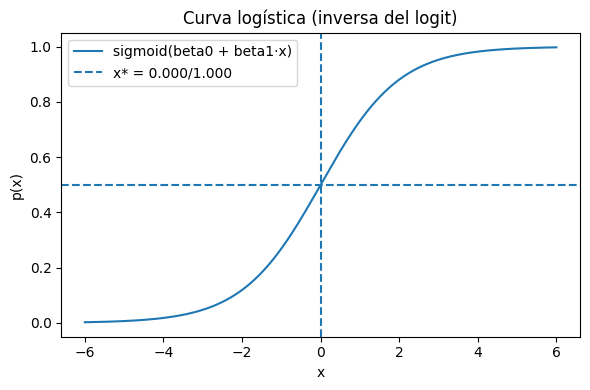

In [42]:
# 1) Curva logística con beta0=0, beta1=1
plot_sigmoid(beta0=0, beta1=1)


## ⚙️ Entrenamiento del modelo de regresión logística - `CountVectorizer`


### 🔬 Paso 1: la mirada **estadística** con `statsmodels`

Antes de saltar a `scikit-learn`, vale la pena estimar el modelo con `statsmodels`, porque nos devuelve la **salida clásica de inferencia**: coeficientes ($\hat\beta$), errores estándar, estadísticos $z$, **p-valores** e intervalos de confianza. Eso es justo lo que necesitamos para *interpretar* el modelo y no solo para predecir.

> ⚠️ **¿Por qué no metemos las 34.967 palabras?**
>
> - Tendríamos **más parámetros que observaciones** ($p \gg n$): con 6.882 reseñas y ~35.000 columnas el modelo no es identificable.
> - La estimación por máxima verosimilitud necesita invertir la **matriz Hessiana** de tamaño $35.000 \times 35.000$ (≈ 9.8 GB en memoria). Inviable.
> - Aparece **separación perfecta**: palabras que solo salen en reseñas positivas empujan $\hat\beta \to \infty$ y los errores estándar explotan.
> - Muchas palabras están **correlacionadas entre sí** (multicolinealidad), lo que infla los errores estándar y vuelve los p-valores poco confiables.
>
> 👉 Por eso, para **entender** el modelo tomamos un puñado de palabras interpretables. Para **predecir** con las 35.000, más adelante usaremos `scikit-learn` con regularización.

Además, en vez de usar el **conteo** de la palabra, usaremos su **presencia** (1 = la palabra aparece en la reseña, 0 = no aparece). Así la interpretación del $\beta$ queda limpia: *"qué le pasa a la probabilidad de que la reseña sea positiva cuando la palabra **aparece**"*.


In [49]:
# --- 1) Elegimos un subconjunto de palabras interpretables ---
features = np.array(bow_counts.get_feature_names_out())
freqs    = np.asarray(X_train_bow.sum(axis=0)).ravel()   # frecuencia total de cada término
vocab    = {t: j for j, t in enumerate(features)}        # término -> índice de columna


In [50]:

# Palabras candidatas (recuerda: el vocabulario está LEMATIZADO y SIN TILDES)
terminos_interes = [
    "bueno", "malo", "mal", "excelente", "aburrir", "aburrido", "obra", "maestro",
    "recomendar", "gustar", "perder", "pena", "genial", "horrible", "interesante",
    "guion", "actuacion", "personaje", "historia", "original", "pesimo", "fantastico",
    "decepcionar", "increible", "tiempo", "final",
]


In [51]:

MIN_FREC = 30   # exigimos que la palabra aparezca al menos 30 veces (si no, el beta es puro ruido)
terminos        = [t for t in terminos_interes if t in vocab and freqs[vocab[t]] >= MIN_FREC]
no_encontrados  = [t for t in terminos_interes if t not in vocab]
poco_frecuentes = [t for t in terminos_interes if t in vocab and freqs[vocab[t]] < MIN_FREC]


In [52]:

# Si quedaron muy pocas, completamos con las palabras más frecuentes del corpus
N_MIN = 12
for j in np.argsort(freqs)[::-1]:
    if len(terminos) >= N_MIN:
        break
    if features[j] not in terminos:
        terminos.append(features[j])

print(f"✅ Términos usados en el modelo ({len(terminos)}):\n{terminos}\n")
print(f"❌ No están en el vocabulario: {no_encontrados}")
print(f"⚠️  Muy poco frecuentes (< {MIN_FREC}): {poco_frecuentes}")


✅ Términos usados en el modelo (23):
['malo', 'excelente', 'aburrir', 'aburrido', 'obra', 'maestro', 'recomendar', 'gustar', 'perder', 'pena', 'genial', 'horrible', 'interesante', 'guion', 'actuacion', 'personaje', 'historia', 'original', 'pesimo', 'fantastico', 'decepcionar', 'increible', 'tiempo']

❌ No están en el vocabulario: ['bueno', 'mal', 'final']
⚠️  Muy poco frecuentes (< 30): []


In [53]:

# --- 2) Matriz de diseño X (presencia 0/1) y respuesta y (1 = positivo) ---
cols = [vocab[t] for t in terminos]
X_sm = pd.DataFrame(
    (X_train_bow[:, cols].toarray() > 0).astype(int),   # 1 si la palabra aparece, 0 si no
    columns=terminos,
    index=y_train.index                                 # mismo índice que y_train
)
X_sm = sm.add_constant(X_sm, has_constant="add")        # agrega el intercepto beta_0
y_sm = y_train.apply(lambda v: 1 if v == "positivo" else 0)

print("\nDimensión de la matriz de diseño:", X_sm.shape)
X_sm.head()


Dimensión de la matriz de diseño: (6882, 24)


,const,malo,excelente,aburrir,aburrido,obra,maestro,recomendar,gustar,perder,...,guion,actuacion,personaje,historia,original,pesimo,fantastico,decepcionar,increible,tiempo
908,1.0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
6933,1.0,1,0,0,1,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
420,1.0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2658,1.0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,1
4092,1.0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


### Ojo

Solo para entender la interpretación estadística en el modelo de regresión lineal, seleccionamos 24 palabras de las más de 34,000 palabras que componen nuestro vocabulario

In [54]:
# --- Estimación por Máxima Verosimilitud (MLE) ---
logit_sm = sm.Logit(y_sm, X_sm).fit()

print(logit_sm.summary())

Optimization terminated successfully.
         Current function value: 0.635745
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:              polaridad   No. Observations:                 6882
Model:                          Logit   Df Residuals:                     6858
Method:                           MLE   Df Model:                           23
Date:                Mon, 24 Aug 2026   Pseudo R-squ.:                 0.07834
Time:                        13:25:18   Log-Likelihood:                -4375.2
converged:                       True   LL-Null:                       -4747.1
Covariance Type:            nonrobust   LLR p-value:                2.575e-142
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
const          -0.2711      0.044     -6.175      0.000      -0.357      -0.185
malo           -0.6515    

### 📋 ¿Cómo se lee esta salida?

**🔹 Bloque superior — el ajuste global del modelo**

| Campo | Qué significa |
|---|---|
| `Dep. Variable` | La variable respuesta ($Y = 1$ si la reseña es *positivo*). |
| `No. Observations` | Número de reseñas de entrenamiento usadas. |
| `Df Model` | Número de predictores (sin contar el intercepto). |
| `Method: MLE` | A diferencia de OLS, aquí **no hay fórmula cerrada**: los $\hat\beta$ se obtienen maximizando la verosimilitud de forma iterativa. |
| `converged: True` | ✅ El algoritmo iterativo encontró el máximo. Si dijera `False`, ¡no interpretes nada! (típicamente indica separación perfecta). |
| `Log-Likelihood` | Log-verosimilitud del modelo ajustado (entre más cercana a 0, mejor). |
| `LL-Null` | Log-verosimilitud del modelo **solo con intercepto** (el modelo "tonto"). |
| `LLR p-value` | Test de razón de verosimilitud: $H_0$ = *todos* los $\beta_j = 0$. Es el análogo al **test F** de la regresión lineal. Si es $< 0.05$, el modelo aporta información. |
| `Pseudo R-squ.` | **McFadden**: $1 - \dfrac{\ell_{\text{modelo}}}{\ell_{\text{nulo}}}$. ⚠️ **NO se lee como el $R^2$ de la regresión lineal**: valores de 0.05–0.2 ya son razonables en datos de texto. No es "% de varianza explicada". |

**🔹 Bloque inferior — un renglón por cada $\beta_j$**

| Columna | Qué significa |
|---|---|
| `coef` | $\hat\beta_j$: el efecto de la palabra **en la escala del logit** (log-odds). |
| `std err` | Error estándar de $\hat\beta_j$: cuánta incertidumbre hay en esa estimación. |
| `z` | Estadístico de **Wald**: $z = \dfrac{\hat\beta_j}{\text{ee}(\hat\beta_j)}$. Es el análogo al estadístico $t$ de la regresión lineal (aquí es $z$ porque el resultado es **asintótico**, válido para $n$ grande). |
| `P>\|z\|` | 🎯 **El p-valor**. Prueba $H_0: \beta_j = 0$ vs. $H_1: \beta_j \neq 0$. Si $p < 0.05$ ⇒ rechazamos $H_0$ ⇒ **esa palabra sí aporta** para distinguir reseñas positivas. |
| `[0.025  0.975]` | Intervalo de confianza al 95% para $\beta_j$. **Regla práctica:** si el intervalo **contiene el 0**, el coeficiente NO es significativo (es la misma conclusión que el p-valor). |

> 🧠 **La gran diferencia con la regresión lineal:** en OLS, $\beta_j$ es *"cuánto cambia $Y$"*. Aquí, $\beta_j$ es *"cuánto cambia el **log-odds** de $Y=1$"*. Para volverlo interpretable hay que **exponenciar**: $e^{\beta_j}$ es el **odds ratio**.


In [55]:
# --- Traducimos los betas a Odds Ratios interpretables ---
tabla = pd.DataFrame({
    "beta":       logit_sm.params,           # efecto en escala log-odds
    "error_std":  logit_sm.bse,
    "z":          logit_sm.tvalues,
    "p_valor":    logit_sm.pvalues,
    "odds_ratio": np.exp(logit_sm.params),   # e^beta  <-- la magia interpretativa
})

ic = np.exp(logit_sm.conf_int())             # IC 95% del odds ratio
tabla["OR_ic_inf"], tabla["OR_ic_sup"] = ic[0], ic[1]

tabla["significativo_5%"] = np.where(tabla["p_valor"] < 0.05, "Sí ✅", "No ❌")
tabla["efecto"] = np.where(tabla["beta"] > 0, "↑ prob. de ser positivo", "↓ prob. de ser positivo")

intercepto = tabla.loc["const"]
tabla = tabla.drop(index="const").sort_values("beta", ascending=False)

print(f"Intercepto (beta_0) = {intercepto['beta']:.4f}  ->  odds base = {intercepto['odds_ratio']:.4f}")
print(f"Probabilidad base (reseña SIN ninguna de estas palabras) = "
      f"{1/(1+np.exp(-intercepto['beta'])):.4f}\n")

tabla.round(4)

Intercepto (beta_0) = -0.2711  ->  odds base = 0.7625
Probabilidad base (reseña SIN ninguna de estas palabras) = 0.4326



,beta,error_std,z,p_valor,odds_ratio,OR_ic_inf,OR_ic_sup,significativo_5%,efecto
fantastico,0.9855,0.1297,7.5953,0.0000,2.6791,2.0775,3.4548,Sí ✅,↑ prob. de ser positivo
genial,0.9738,0.1149,8.4764,0.0000,2.6481,2.1142,3.3169,Sí ✅,↑ prob. de ser positivo
excelente,0.9355,0.0999,9.3605,0.0000,2.5485,2.0951,3.0999,Sí ✅,↑ prob. de ser positivo
obra,0.5637,0.0946,5.9576,0.0000,1.7571,1.4597,2.1152,Sí ✅,↑ prob. de ser positivo
increible,0.5010,0.1441,3.4768,0.0005,1.6505,1.2443,2.1891,Sí ✅,↑ prob. de ser positivo
actuacion,0.3836,0.0790,4.8571,0.0000,1.4676,1.2571,1.7133,Sí ✅,↑ prob. de ser positivo
gustar,0.3615,0.0654,5.5290,0.0000,1.4355,1.2628,1.6317,Sí ✅,↑ prob. de ser positivo
historia,0.2291,0.0540,4.2402,0.0000,1.2575,1.1311,1.3980,Sí ✅,↑ prob. de ser positivo
tiempo,0.1608,0.0699,2.2992,0.0215,1.1745,1.0240,1.3470,Sí ✅,↑ prob. de ser positivo
maestro,0.0943,0.1392,0.6774,0.4982,1.0989,0.8365,1.4435,No ❌,↑ prob. de ser positivo


### 🧮 Cómo se analizan los $\beta$ (¡lo importante!)

Recordemos el modelo:

$$\ln\left(\frac{\pi_i}{1-\pi_i}\right) = \beta_0 + \beta_1 x_{1i} + \cdots + \beta_p x_{pi}$$

**1️⃣ El signo del $\beta$ → la dirección del efecto**

- $\beta_j > 0$ ⇒ cuando la palabra aparece, **sube** el log-odds ⇒ **sube** la probabilidad de que la reseña sea positiva. 👍
- $\beta_j < 0$ ⇒ cuando la palabra aparece, **baja** la probabilidad de ser positiva. 👎
- $\beta_j = 0$ ⇒ la palabra es irrelevante (odds ratio = 1).

**2️⃣ La magnitud → se interpreta con el odds ratio $e^{\beta_j}$**

$$OR_j = e^{\beta_j} = \frac{\text{odds}(Y=1 \mid \text{la palabra aparece})}{\text{odds}(Y=1 \mid \text{la palabra NO aparece})}$$

Manteniendo **todo lo demás constante** (*ceteris paribus*), si la palabra aparece, los **odds** de que la reseña sea positiva se **multiplican** por $e^{\beta_j}$.

- $e^{\beta_{fantastico}} = 3.45$ ⇒ los odds de ser positiva se vuelven **3.45 veces** mayores *(un aumento del 245%)*.
- $e^{\beta_{perder}} = 0.81$ ⇒ los odds **se reducen** por un factor de 0.81 (o se reduce un 19%) la razón de odds cuando aparece esta palabra
- $e^{\beta_{personaje}} = 1$ ⇒ sin efecto, esta palabra no afecta los odds que el comentario sea positivo o negativo


⚠️ El OR multiplica **odds**, no probabilidades. Duplicar los odds **no** duplica la probabilidad.

**3️⃣ El p-valor → ¿el efecto es real o es ruido?**

$$H_0: \beta_j = 0 \quad \text{vs.} \quad H_1: \beta_j \neq 0, \qquad z = \frac{\hat\beta_j}{\text{ee}(\hat\beta_j)}$$

- $p < 0.05$ ⇒ **rechazamos** $H_0$: hay evidencia de que la palabra sí discrimina. El IC del OR **no contiene el 1**.
- $p \geq 0.05$ ⇒ **no rechazamos** $H_0$: no hay evidencia suficiente. El IC del OR **contiene el 1**. Ojo: esto **no prueba** que $\beta_j = 0$, solo que con estos datos no lo podemos distinguir de 0 (suele pasar con palabras poco frecuentes → error estándar grande).

**4️⃣ Advertencias que deben quedar claras ☢️**

- 🚫 **Esto no es causalidad.** Que aparezca "genial" no *causa* una buena calificación; simplemente van juntas.
- 🔗 **Los $\beta$ son efectos parciales**, ajustados por las demás palabras del modelo. Si sacamos o metemos palabras, los coeficientes cambian.
- 🙃 **Cuidado con la negación:** el modelo bolsa-de-palabras no ve *"no es buena"*, ve *"bueno"*. Por eso una palabra aparentemente positiva puede salir con $\beta$ negativo. ¡Es un excelente tema de discusión al mirar la tabla de arriba!
- 📉 **Significativo ≠ importante.** Con $n$ grande, efectos minúsculos salen significativos. Mira siempre el **tamaño** del OR, no solo el p-valor.
- 🎯 Los p-valores asumen un modelo **fijo, elegido antes** de ver los datos. Si escogiéramos las palabras mirando cuáles funcionan mejor, los p-valores quedarían sesgados (*selección post-hoc*).


In [56]:
# --- Efectos marginales: el mismo beta, pero en escala de PROBABILIDAD ---
# dy/dx = cuánto cambia (en promedio) la probabilidad de que la reseña sea positiva
#         cuando la palabra pasa de ausente a presente.
print(logit_sm.get_margeff(at="overall", method="dydx").summary())

        Logit Marginal Effects       
Dep. Variable:              polaridad
Method:                          dydx
At:                           overall
                 dy/dx    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
malo           -0.1454      0.016     -9.092      0.000      -0.177      -0.114
excelente       0.2088      0.022      9.588      0.000       0.166       0.252
aburrir        -0.2590      0.038     -6.803      0.000      -0.334      -0.184
aburrido       -0.2886      0.035     -8.300      0.000      -0.357      -0.220
obra            0.1258      0.021      6.015      0.000       0.085       0.167
maestro         0.0210      0.031      0.677      0.498      -0.040       0.082
recomendar     -0.0029      0.058     -0.051      0.959      -0.116       0.110
gustar          0.0807      0.014      5.575      0.000       0.052       0.109
perder         -0.0844      0.020     -4.286    

📝 Reseña: andar rodeo pelicula increiblemente malo aburrido gasteis euro pelicula horrenda guion espantoso pequeño trama dani rovira poquito gracia resto maria valverde papel carrera trama amiga autobus prender el fuego pelicula hecha explotar fenomeno apellido vasco destruir cine español ...

🔤 Palabras del modelo presentes: ['malo', 'aburrido', 'guion']

➕ Aporte de cada término al log-odds:
   (intercepto)    -0.2711
   malo            -0.6515   (OR = 0.521)
   aburrido        -1.2927   (OR = 0.275)
   guion           -0.1601   (OR = 0.852)

🧮 eta (log-odds) = -2.3755
📈 pi = 1/(1+e^-eta) = 0.0851   -> statsmodels dice: 0.0851
🔮 Predicción con umbral 0.5: negativo-neutro
✅ Valor real: negativo-neutro


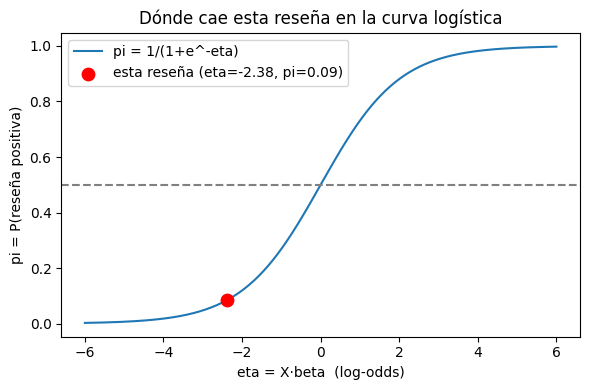

In [57]:
# --- Sigamos el modelo "a mano" sobre una reseña concreta ---
# Buscamos una reseña de entrenamiento que contenga varias de nuestras palabras
mascara = X_sm[terminos].sum(axis=1) >= 3
i = int(np.argmax(mascara.values))          # posición de la primera que cumple

x_i       = X_sm.iloc[[i]]
presentes = [t for t in terminos if x_i[t].iloc[0] == 1]

# 1) Predictor lineal: eta = beta_0 + sum(beta_j * x_j)
eta = float((x_i.values @ logit_sm.params.values).item())
# 2) Lo pasamos por la función logística para obtener la probabilidad
pi  = 1 / (1 + np.exp(-eta))

print("📝 Reseña:", X_train.iloc[i][:300], "...\n")
print("🔤 Palabras del modelo presentes:", presentes)
print("\n➕ Aporte de cada término al log-odds:")
print(f"   {'(intercepto)':<15} {logit_sm.params['const']:+.4f}")
for t in presentes:
    print(f"   {t:<15} {logit_sm.params[t]:+.4f}   (OR = {np.exp(logit_sm.params[t]):.3f})")

print(f"\n🧮 eta (log-odds) = {eta:+.4f}")
print(f"📈 pi = 1/(1+e^-eta) = {pi:.4f}   -> statsmodels dice: {logit_sm.predict(x_i).iloc[0]:.4f}")
print(f"🔮 Predicción con umbral 0.5: {'positivo' if pi >= 0.5 else 'negativo-neutro'}")
print(f"✅ Valor real: {y_train.iloc[i]}")

# Y lo ubicamos sobre la curva logística: eta vive en los reales, pi vive en [0, 1]
eje = np.linspace(-6, 6, 400)
plt.figure(figsize=(6, 4))
plt.plot(eje, 1 / (1 + np.exp(-eje)), label="pi = 1/(1+e^-eta)")
plt.axhline(0.5, linestyle="--", color="gray")
plt.scatter([eta], [pi], color="red", zorder=5, s=80, label=f"esta reseña (eta={eta:.2f}, pi={pi:.2f})")
plt.xlabel("eta = X·beta  (log-odds)")
plt.ylabel("pi = P(reseña positiva)")
plt.title("Dónde cae esta reseña en la curva logística")
plt.legend()
plt.tight_layout()
plt.show()

### 🔁 `statsmodels` vs. `scikit-learn`

| | `statsmodels` (`sm.Logit`) | `scikit-learn` (`LogisticRegression`) |
|---|---|---|
| **Objetivo** | **Explicar**: inferencia sobre los $\beta$ | **Predecir**: minimizar el error fuera de muestra |
| **Salida** | p-valores, errores estándar, IC, verosimilitud | solo `coef_` (sin medida de incertidumbre) |
| **Regularización** | Ninguna por defecto (MLE puro) | 🔴 **L2 activada por defecto** (`C=1.0`) |
| **Escalabilidad** | Se ahoga con miles de columnas | Maneja 35.000 columnas dispersas sin problema |

> 🔑 **Detalle clave:** como `scikit-learn` regulariza por defecto, sus coeficientes están **encogidos hacia 0** y por eso **no son comparables** uno a uno con los de `statsmodels`, ni admiten p-valores. La regularización es justamente lo que le permite sobrevivir a las 34.967 palabras: penaliza los $\beta$ grandes y evita la separación perfecta.

👉 Con esa intuición ya construida, ahora sí estimemos el modelo **completo** (todas las palabras) con `scikit-learn`:


In [58]:
# Pero en la práctica es más común usar la implementación de scikit-learn, que es más rápida y flexible.
# --- 1) Entrenar ---
logreg_count = LogisticRegression(max_iter=2000, solver='lbfgs')
logreg_count.fit(X_train_bow, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,2000
,multi_class,'deprecated'


## 🧪 Métricas de evaluación

Para evaluar modelos de clasificación, usamos varias métricas que parten de la matriz de confusión. Aquí te dejo las más importantes, con intuición, fórmulas y cuándo usarlas. 🚀

### 🔢 Matriz de confusión

La matriz de confusión cruza la verdad terreno (Ground Truth) con lo predicho por el modelo:

 - TP (True Positive) → positivos bien clasificados ✅
 - TN (True Negative) → negativos bien clasificados ✅
 - FP (False Positive) → negativos clasificados como positivos ❌ (error tipo I)
 - FN (False Negative) → positivos clasificados como negativos ❌ (error tipo II)

No es una métrica por sí sola, pero es la base de casi todas.

🔎 Define claramente qué clase es la positiva (la de interés). Las métricas dependen de esa convención.

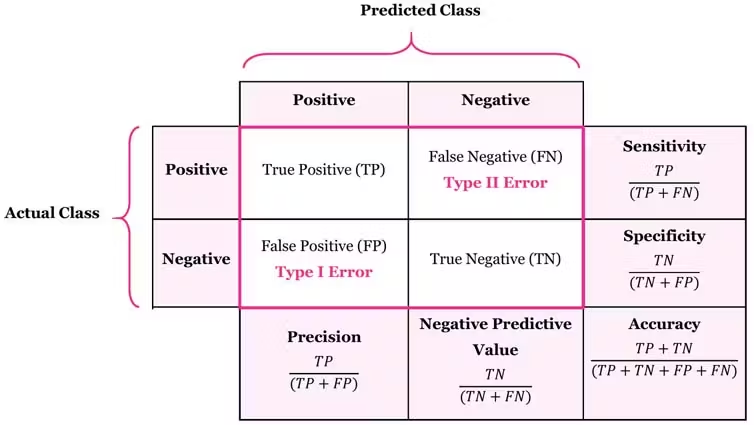


### 🎯 Accuracy (exactitud)

La precisión de la clasificación es quizás la métrica más sencilla de usar e implementar y se define como el número de predicciones correctas dividido por el número total de predicciones, multiplicado por 100 . 

$$Accuracy = \dfrac{TP + TN}{TP + FP + FN + TN}$$

 - 👍 Sencilla y útil con clases balanceadas.
 - ⚠️ Puede ser engañosa cuando la clase positiva es rara.
 - 🎯 Precision (precisión) y Recall (exhaustividad)

### 🎯 Precision (precisión) y Recall (exhaustividad)

 1. Precision: “de todo lo que predije positivo, ¿cuánto fue correcto?”:

 $$Precision = \dfrac{TP}{TP + FP}$$
 
 2. Recall (TPR, sensibilidad): “de todos los positivos reales, ¿cuántos detecté?”:
 
 $$Recall = \dfrac{TP}{TP + FN}$$

💡 Trade-off: subir precision suele bajar recall y viceversa (depende del umbral).

### 🎯 F1-score

Media armónica entre precision y recall (balancea ambos).

$$F1 = 2\times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$


👍 Útil cuando quieres equilibrio y hay desbalance.

### 📈 ROC y AUC-ROC

La curva ROC grafica $TPR$ vs $FPR$ (tasa de falsos positivos) para diferentes thresholds en la probabilidad de $\hat{y}$.

El área bajo la curva AUC-ROC mide la capacidad de ranking global del modelo (1 = perfecto).

 - 👍 Buena con datasets balanceados.
 - ⚠️ En desbalance severo, puede verse “optimista”.

 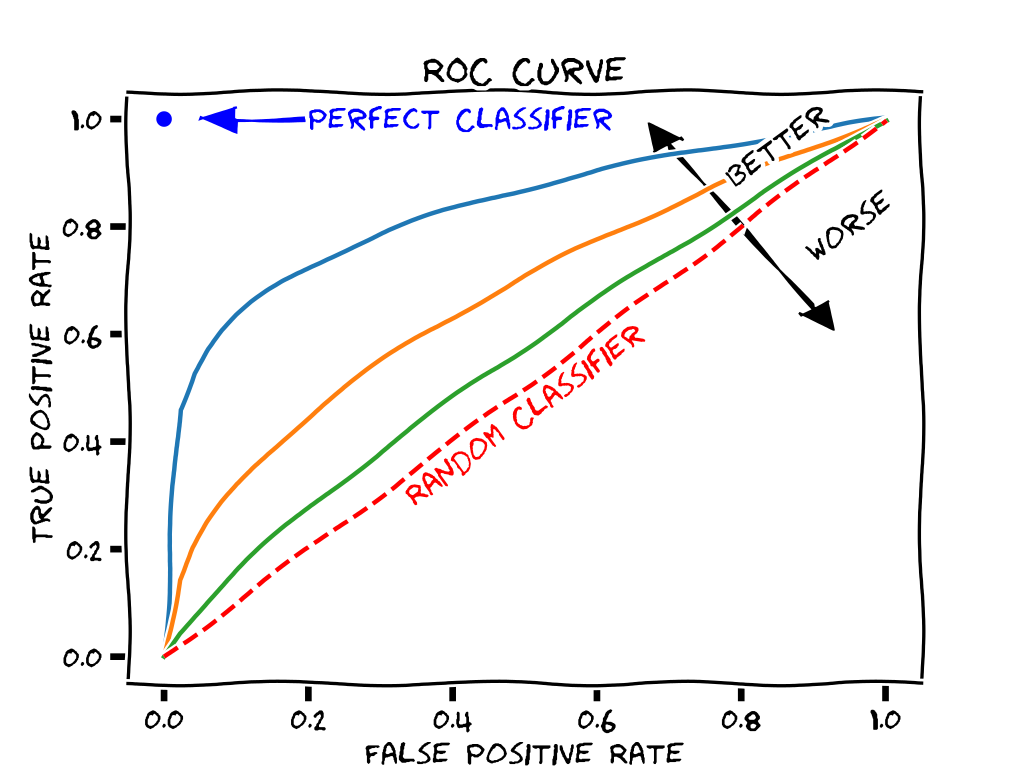

 <sub><i>Fuente: <a href="https://polmartisanahuja.com/entendiendo-la-curva-roc-y-el-auc-dos-medidas-del-rendimiento-de-un-clasificador-binario-que-van-de-la-mano/">
Pol Martí Sanahuja — “Entendiendo la curva ROC y el AUC...”</a>. Consultado el 18-08-2025.</i></sub>

### 📈 PR y AUC-PR (Average Precision)

La curva Precision–Recall muestra el trade-off entre ambas.
El área AUC-PR (o Average Precision) resume el desempeño enfocándose en la clase positiva.

- 👍 Preferible cuando la clase positiva es rara.
- 💬 Más informativa que ROC en desbalance fuerte.

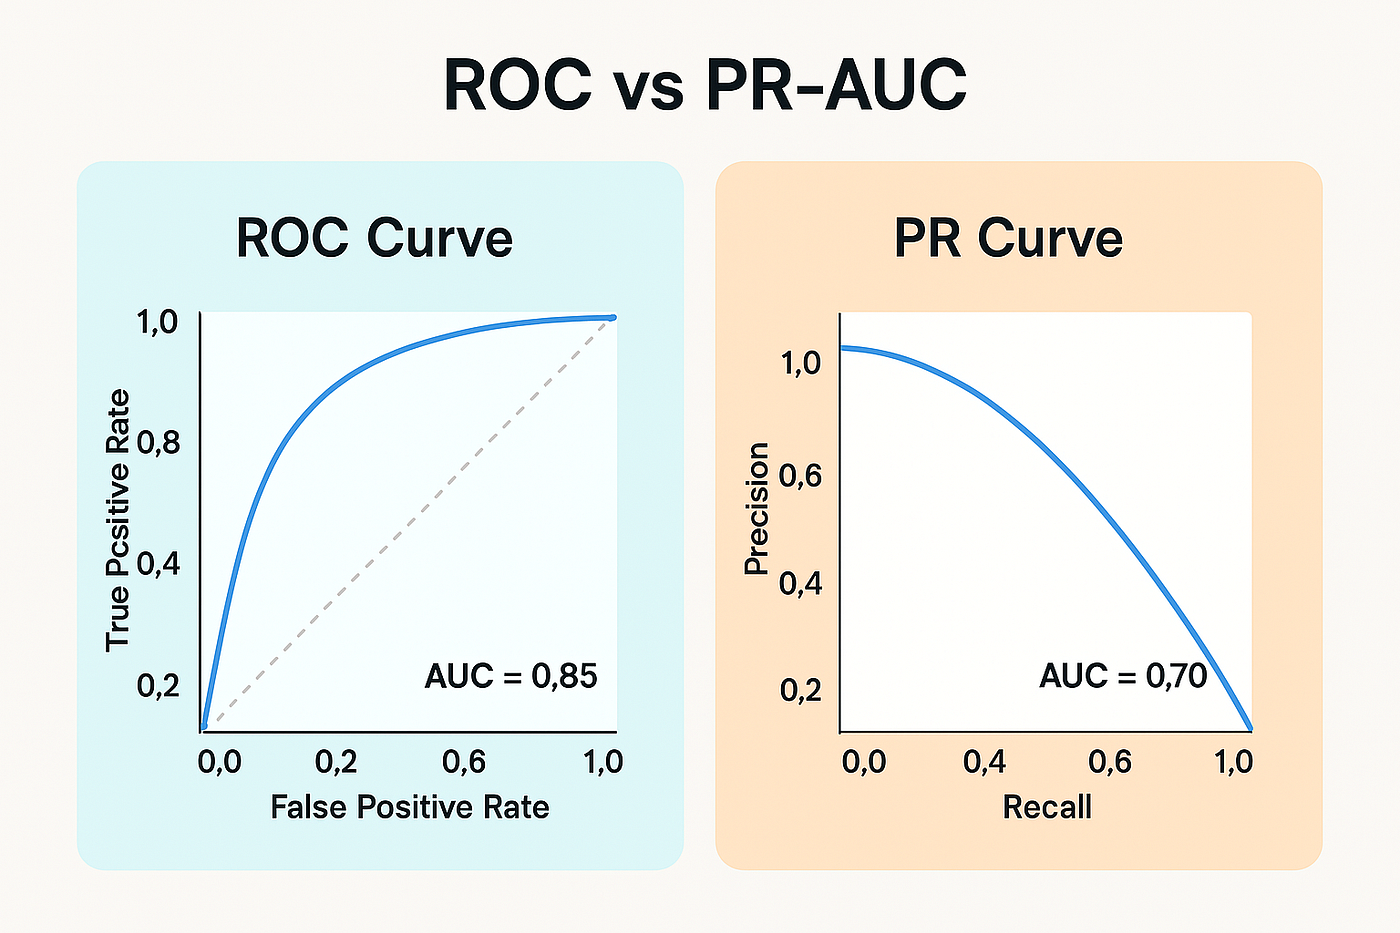

### 🧮 Multiclase: ¿cómo promediar?

Macro: promedio simple por clase (trata a todas igual).

Weighted: promedio ponderado por soporte (acomoda desbalance).

Micro: agrega TP/FP/FN globalmente (útil para ranking global).



In [59]:
# --- 2) Predecir ---
y_pred_train = logreg_count.predict(X_train_bow)

# --- 3) Métricas básicas ---
print("Accuracy:", accuracy_score(y_train, y_pred_train))
print("\nClassification report:\n", classification_report(y_train, y_pred_train))

Accuracy: 0.9960767218831735

Classification report:
                  precision    recall  f1-score   support

negativo-neutro       1.00      1.00      1.00      3723
       positivo       1.00      0.99      1.00      3159

       accuracy                           1.00      6882
      macro avg       1.00      1.00      1.00      6882
   weighted avg       1.00      1.00      1.00      6882



In [60]:
# --- 2) Predecir ---
y_pred = logreg_count.predict(X_test_bow)

# --- 3) Métricas básicas ---
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification report:\n", classification_report(y_test, y_pred))


Accuracy: 0.7536316095293434

Classification report:
                  precision    recall  f1-score   support

negativo-neutro       0.78      0.77      0.78       960
       positivo       0.72      0.73      0.72       761

       accuracy                           0.75      1721
      macro avg       0.75      0.75      0.75      1721
   weighted avg       0.75      0.75      0.75      1721



1. `negativo-neutro`

 - precision = 0.78 → cuando el modelo predice “negativo-neutro”, acierta el 78% (22% son falsos positivos).
 - recall = 0.77 → recupera el 77% de los casos realmente “negativo-neutro” (23% quedaron como falsos negativos).
 - f1 = 0.78 → equilibrio entre precision y recall.
 - support = 960 → había 960 ejemplos de esta clase en el test.

2. `positivo`

 - precision = 0.72 → de las predicciones “positivo”, el 72% eran correctas (28% FP).
 - recall = 0.73 → captura el 73% de los positivos reales (27% FN).
 - f1 = 0.72
 - support = 761

3. `accuracy` = 0.75 → proporción total bien clasificada (sobre 1721 casos).

4. `macro avg` (promedio simple entre clases) ≈ 0.75–0.75 → trata a ambas clases por igual; útil si te importa equidad entre clases.
5. `weighted avg` (ponderado por support) ≈ 0.75–0.75 → refleja el leve desbalance (960 vs 761).

La cercanía entre macro y weighted sugiere que el desbalance no es extremo.

In [61]:

# Matriz de confusión
cm = confusion_matrix(y_test, y_pred)
cm_df = pd.DataFrame(cm, index=[f"true_{c}" for c in logreg_count.classes_],
                         columns=[f"pred_{c}" for c in logreg_count.classes_])
print("\nConfusion matrix:\n", cm_df)



Confusion matrix:
                       pred_negativo-neutro  pred_positivo
true_negativo-neutro                   742            218
true_positivo                          206            555


In [62]:
unique_classes = np.unique(y_train)
y_proba = logreg_count.predict_proba(X_test_bow)[:, 1]
try:
    print("ROC-AUC:", roc_auc_score(y_test, y_proba))
except Exception:
    # Fallback si y_test no es numérico:
    mapping = {cls: i for i, cls in enumerate(sorted(unique_classes))}
    y_test_bin = pd.Series(y_test).map(mapping)
    print("ROC-AUC:", roc_auc_score(y_test_bin, y_proba))


ROC-AUC: 0.828322109067017


In [63]:
feature_names = np.array(bow_counts.get_feature_names_out())
coefs = logreg_count.coef_[0]
top_pos_idx = np.argsort(coefs)[-15:]
top_neg_idx = np.argsort(coefs)[:15]

print("\nTop términos clase positiva:")
print(list(zip(feature_names[top_pos_idx], np.round(coefs[top_pos_idx], 3))))

print("\nTop términos clase negativa:")
print(list(zip(feature_names[top_neg_idx], np.round(coefs[top_neg_idx], 3))))
    



Top términos clase positiva:
[('complejo', np.float64(1.011)), ('desmerecir', np.float64(1.016)), ('notable', np.float64(1.029)), ('suerte', np.float64(1.036)), ('envidiar', np.float64(1.037)), ('extraordinario', np.float64(1.059)), ('fabula', np.float64(1.065)), ('vosotro', np.float64(1.082)), ('maravilloso', np.float64(1.097)), ('bravo', np.float64(1.109)), ('pega', np.float64(1.111)), ('genial', np.float64(1.173)), ('encantar', np.float64(1.194)), ('recomendable', np.float64(1.209)), ('pelin', np.float64(1.476))]

Top términos clase negativa:
[('pesimo', np.float64(-1.528)), ('previsible', np.float64(-1.272)), ('flojo', np.float64(-1.266)), ('verguenza', np.float64(-1.172)), ('aprobado', np.float64(-1.153)), ('patetico', np.float64(-1.153)), ('aceptable', np.float64(-1.144)), ('aburrir', np.float64(-1.124)), ('pasable', np.float64(-1.086)), ('aburrido', np.float64(-1.067)), ('mover', np.float64(-1.051)), ('estrella', np.float64(-1.031)), ('cuajar', np.float64(-1.026)), ('sobremesa'

Umbral (Youden J): 0.3057
Umbral (Dist. a (0,1) mínima): 0.3647
Umbral (mejor F1 en PR): 0.3057


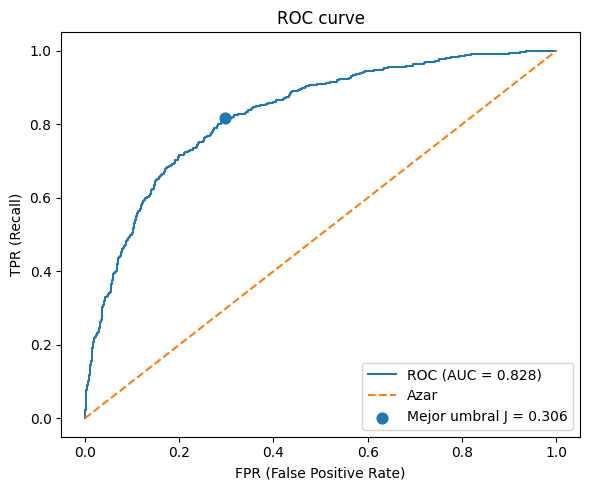

In [64]:
# --- 2) ROC ---
y_test_bin = (y_test == "positivo").astype(int)

# Calcula ROC y AUC
fpr, tpr, thr_roc = roc_curve(y_test_bin, y_proba)  # guarda thresholds
auc_roc = roc_auc_score(y_test_bin, y_proba)

# (A) Mejor umbral por Youden's J = TPR - FPR
youden = tpr - fpr
idx_j = np.argmax(youden)
thr_j = thr_roc[idx_j]
fpr_j, tpr_j = fpr[idx_j], tpr[idx_j]

# (B) (Opcional) Menor distancia a (0,1)
dist = np.sqrt((fpr - 0)**2 + (tpr - 1)**2)
idx_d = np.argmin(dist)
thr_d = thr_roc[idx_d]
fpr_d, tpr_d = fpr[idx_d], tpr[idx_d]

# (C) (Opcional) Mejor F1 en curva PR (útil si la positiva es rara)
prec, rec, thr_pr = precision_recall_curve(y_test_bin, y_proba)
f1s = 2 * (prec * rec) / (prec + rec + 1e-12)
idx_f1 = np.nanargmax(f1s[:-1])  # el último punto no tiene umbral
thr_f1 = thr_pr[idx_f1]

print(f"Umbral (Youden J): {thr_j:.4f}")
print(f"Umbral (Dist. a (0,1) mínima): {thr_d:.4f}")
print(f"Umbral (mejor F1 en PR): {thr_f1:.4f}")

# --- Plot ROC con el punto del mejor umbral (Youden J) ---
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f"ROC (AUC = {auc_roc:.3f})")
plt.plot([0,1], [0,1], linestyle="--", label="Azar")

# Marca el mejor punto (Youden J)
plt.scatter([fpr_j], [tpr_j], s=60, marker='o',
            label=f"Mejor umbral J = {thr_j:.3f}")

# (Opcional) marca el de mínima distancia
# plt.scatter([fpr_d], [tpr_d], s=60, marker='s',
#             label=f"Min dist (thr={thr_d:.3f})")

plt.xlabel("FPR (False Positive Rate)")
plt.ylabel("TPR (Recall)")
plt.title("ROC curve")
plt.legend()
plt.tight_layout()
plt.show()

Mejor umbral (F1 máx): 0.3057
Precision=0.685  Recall=0.816  F1=0.745
Average Precision (AP): 0.782


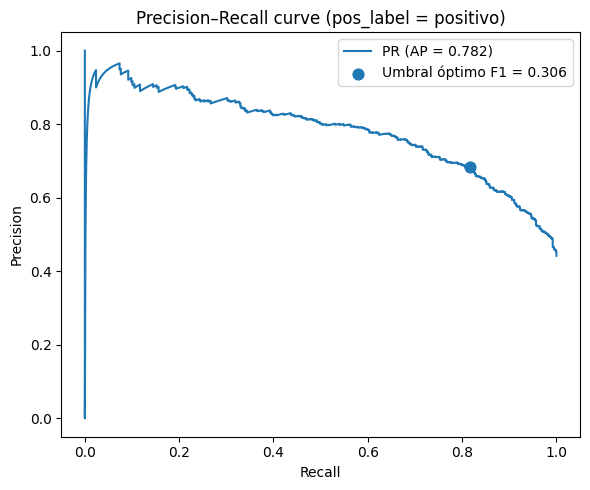

In [65]:
pos_label = logreg_count.classes_[1]

# Curva PR (nota: len(thr_pr) = len(prec) - 1)
prec, rec, thr_pr = precision_recall_curve(y_test_bin, y_proba)
ap = average_precision_score(y_test_bin, y_proba)

# F1 en cada punto de la curva (el último punto no tiene umbral)
f1s = 2 * (prec * rec) / (prec + rec + 1e-12)
best_idx = np.nanargmax(f1s[:-1])      # evitar el último punto sin umbral
best_thr = thr_pr[best_idx]
best_prec = prec[best_idx]
best_rec = rec[best_idx]
best_f1 = f1s[best_idx]

print(f"Mejor umbral (F1 máx): {best_thr:.4f}")
print(f"Precision={best_prec:.3f}  Recall={best_rec:.3f}  F1={best_f1:.3f}")
print(f"Average Precision (AP): {ap:.3f}")

# Predicciones con el mejor umbral (si quieres usarlas)
y_pred_best = (y_proba >= best_thr).astype(int)

# --- Plot PR con el punto óptimo ---
plt.figure(figsize=(6,5))
plt.plot(rec, prec, label=f"PR (AP = {ap:.3f})")
plt.scatter([best_rec], [best_prec], s=60, marker='o',
            label=f"Umbral óptimo F1 = {best_thr:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(f"Precision–Recall curve (pos_label = {pos_label})")
plt.legend()
plt.tight_layout()
plt.show()

In [66]:
# --- 1) Usa el umbral óptimo que ya calculaste ---
thr_opt = best_thr   # p.ej., el que maximizó F1 en la curva PR

# --- 2) Probabilidades para la clase positiva ---
pos_label = logreg_count.classes_[1]
neg_label = logreg_count.classes_[0]
pos_idx = list(logreg_count.classes_).index(pos_label)

# Si tu test es BoW:
y_proba = logreg_count.predict_proba(X_test_bow)[:, pos_idx]
# (si usas TF-IDF, cambia X_test_bow por X_test_tfidf o reutiliza y_proba_tfid)

# --- 3) Predicción con umbral custom ---
y_pred_thr = np.where(y_proba >= thr_opt, pos_label, neg_label)

# --- 4) Métricas con el nuevo umbral ---
print("Accuracy:", accuracy_score(y_test, y_pred_thr))
print("\nClassification report (umbral óptimo):\n",
      classification_report(y_test, y_pred_thr))

Accuracy: 0.7524694944799535

Classification report (umbral óptimo):
                  precision    recall  f1-score   support

negativo-neutro       0.83      0.70      0.76       960
       positivo       0.68      0.82      0.74       761

       accuracy                           0.75      1721
      macro avg       0.76      0.76      0.75      1721
   weighted avg       0.76      0.75      0.75      1721



## 🔎 Escenarios con matrices de confusión y qué te dicen del modelo

Formato (binario) que usaré en los ejemplos:

|                | $\text{Pred }+$ | $\text{Pred }-$ |
|:--------------:|:---------------:|:---------------:|
| $\text{Real }+$ | $\mathrm{TP}$   | $\mathrm{FN}$   |
| $\text{Real }-$ | $\mathrm{FP}$   | $\mathrm{TN}$   |

### 0) 🎯 “Peligrosamente perfecto” (muy alta precisión y muy alto recall)

|                | $\text{Pred }+$ | $\text{Pred }-$ |
|:--------------:|:---------------:|:---------------:|
| $\text{Real }+$ | $100$   | $0$   |
| $\text{Real }-$ | $0$   | $900$   |


 - Señales: Todos los estadísticos de desempeño en 100%
 - Acciones: Sobre-ajuste del modelo, más adelante tomaremos acciones en estos casos


### 1) 🎯 “Casi perfecto” (alta precisión y alta recall)

|                | $\text{Pred }+$ | $\text{Pred }-$ |
|:--------------:|:---------------:|:---------------:|
| $\text{Real }+$ | $95$   | $5$   |
| $\text{Real }-$ | $6$   | $894$   |

 - Señales: diagonal dominante; pocos FP y FN.
 - Acciones: valida que no haya fuga de información; compara con un baseline simple.

### 2) 🧲 Alta precision, baja recall (muchos FN)

|                | $\text{Pred }+$ | $\text{Pred }-$ |
|:--------------:|:---------------:|:---------------:|
| $\text{Real }+$ | $40$   | $60$   |
| $\text{Real }-$ | $5$   | $895$   |

 - Señales: el modelo “se cuida” de marcar positivos → pierde muchos casos reales.
 - Cuándo pasa: umbral alto, clase + costosa de etiquetar, o desbalance.
 - Acciones: baja el umbral para subir recall; usa class_weight='balanced'; optimiza F1/Recall.

### 3) 🚨 Alta recall, baja precision (muchos FP)

|                | $\text{Pred }+$ | $\text{Pred }-$ |
|:--------------:|:---------------:|:---------------:|
| $\text{Real }+$ | $90$   | $10$   |
| $\text{Real }-$ | $150$   | $750$   |

 - Señales: el modelo “dispara” muchos positivos, pero se equivoca con frecuencia.
 - Cuándo pasa: umbral bajo, features poco específicas.
 - Acciones: sube el umbral; añade features más discriminativas (p. ej., bigramas, manejo de negación en texto), regulariza mejor.

### 4) 📉 “Accuracy alto” por desbalance

|                | $\text{Pred }+$ | $\text{Pred }-$ |
|:--------------:|:---------------:|:---------------:|
| $\text{Real }+$ | $5$   | $95$   |
| $\text{Real }-$ | $0$   | $900$   |

 - Señales: accuracy ~90%, pero recall de la clase + es pésimo.
 - Cuándo pasa: clase positiva rara.
 - Acciones: reporta F1 y PR/AUC-PR; re-muestreo, class_weight, umbral enfocado a recall.

### 5) 💤 Clasificador trivial (siempre “negativo”) (O siempre "positivo") 

|                | $\text{Pred }+$ | $\text{Pred }-$ |
|:--------------:|:---------------:|:---------------:|
| $\text{Real }+$ | $0$   | $100$   |
| $\text{Real }-$ | $0$   | $900$   |

 - Señales: nunca predice “+” (nunca predice "-").
 - Cuándo pasa: mal entrenado, umbral extremo, o fuerte desbalance sin medidas.
 - Acciones: revisa pipeline, umbral, pérdida/clase peso, datos.

### 6) 🔃 Etiquetas invertidas (o target mal mapeado)
	
|                | $\text{Pred }+$ | $\text{Pred }-$ |
|:--------------:|:---------------:|:---------------:|
| $\text{Real }+$ | $5$   | $95$   |
| $\text{Real }-$ | $895$   | $5$   |

 - Señales: parece “todo al revés”.
 - Acciones: verifica mapeo de etiquetas, orden de classes_, preprocessing del target.

### 7) 🎚️ Umbral mal calibrado

 - Síntoma: la matriz cambia drásticamente al variar el umbral (de 0.3 a 0.7).

 - Acciones: traza PR/ROC, elige umbral según costo FP/FN (max F1, o precisión/recall objetivo); considera CalibratedClassifierCV.

### 8) 🧪 Sobreajuste (train perfecto, test flojo)

 - Train: diagonal casi perfecta.

 - Test: más FP/FN, confusiones nuevas.
 - Acciones: más datos, regularización, reducción de vocabulario (min_df, max_df, ngram_range), validación estricta.

## 🤖 TfidfVectorizer

TfidfVectorizer convierte documentos de texto en una matriz TF-IDF: pondera cada término por su frecuencia en el documento y lo descuenta si aparece en muchos documentos. Así resalta palabras características y atenúa las demasiado comunes. 🔍

El tf-idf vectorizer python tiene en cuenta el número de veces que aparece la palabra (o token) en dicho documento, pero también el total de veces que aparece en todo el corpus.

 - Los tokens muy frecuentes a nivel de documento y de corpus (posibles stopwords) obtendrán un valor de TF-IDF Vectorizer bajo.
 - Los tokens que aparecen solo en ciertos documentos del corpus tendrán un IDF mayor que aquellos que aparecen en mayor número de documentos.

### 🧠 Intuición

 - $tf$ (Term Frequency): cuántas veces aparece el término $𝑡$ en el documento $𝑑$.
  $$tf(t, d) = \#(t\text{ en } d) $$
 - $IDF$ (Inverse Document Frequency): penaliza términos muy presentes en el corpus.
 $$idf(t) = log\Big(\dfrac{1+N}{1+df(t)}\Big)+1$$
 - $TF-IDF$: frecuencia relativa de aparación penalizada por palabras con mayor frecuencia global
 $$\text{tf-idf}(t, d)= tf(t, d)\cdot idf(t)$$

In [107]:
from sklearn.feature_extraction.text import TfidfVectorizer

docs = ["gato come pescado", "perro come carne", "gato y perro"]

# sin normalizar para ver tf*idf “crudo”
tfidf = TfidfVectorizer(norm="l1")
X = tfidf.fit_transform(docs)

print("Términos:", tfidf.get_feature_names_out())

print("IDF:", tfidf.idf_)  # en el mismo orden que las columnas
print("TF-IDF:\n", X.toarray())


Términos: ['carne' 'come' 'gato' 'perro' 'pescado']
IDF: [1.69314718 1.28768207 1.28768207 1.28768207 1.69314718]
TF-IDF:
 [[0.         0.30167006 0.30167006 0.         0.39665988]
 [0.39665988 0.30167006 0.         0.30167006 0.        ]
 [0.         0.         0.5        0.5        0.        ]]


### 🧭 ¿Cuándo usar TF-IDF?

 - Cuando quieres discriminar términos comunes vs. distintivos.
 - Funciona muy bien con modelos lineales (LogReg/SVM) y para búsqueda/similaridad (coseno).
 - Suele mejorar sobre conteos puros en textos generales.

### ✅ Buenas prácticas

 - Fit en train, transform en test (evita fuga).
 - Controla el tamaño del vocabulario con min_df, max_df, ngram_range, max_features.
 - Prueba sublinear_tf=True y n-gramas (1,2) como baseline sólido.
 - Si el dataset está desbalanceado, evalúa con F1 y AUC-PR, no solo accuracy.

In [108]:
bow_counts_tfid = TfidfVectorizer(
        tokenizer=str.split, preprocessor=None, lowercase=False,
        min_df=3, ngram_range=(1,2), sublinear_tf=True
    )

In [109]:
#Creation of encoding related to train dataset
X_train_bow_tfid = bow_counts_tfid.fit_transform(X_train)
#Transformation of test dataset with train encoding
X_test_bow_tfid = bow_counts_tfid.transform(X_test)

c:\venvs\ad\lib\site-packages\sklearn\feature_extraction\text.py:517: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


In [110]:
# Tamaño: (n_docs, n_terminos)
X_train_bow_tfid.shape

(6882, 36796)

In [111]:
# Porcentaje de celdas no-cero (qué tan densa es)
density = X_train_bow_tfid.nnz / (X_train_bow_tfid.shape[0] * X_train_bow_tfid.shape[1])
print(f"Densidad: {density:.6f}")

Densidad: 0.002490


In [112]:
# Nombres de términos (columnas)
features = bow_counts_tfid.get_feature_names_out()
print(len(features), "términos")
print(features[:20])  # muestra algunos

36796 términos
['aar' 'aar ashmore' 'abad' 'abad marcos' 'abajo' 'abanderado'
 'abandonado' 'abandonado suerte' 'abandonar' 'abandonar el'
 'abandonar sala' 'abandono' 'abanico' 'abarcar' 'abarco' 'abarrotado'
 'abarrotar' 'abatimiento' 'abc' 'abdominal']


In [113]:
# Términos no-cero del doc 0 (y sus conteos)
row = 0
nz_cols = X_train_bow_tfid[row].nonzero()[1]
print([(features[j], X_train_bow_tfid[row, j]) for j in nz_cols])

[('tele', np.float64(0.15040177388070425)), ('restar', np.float64(0.16013696092351462)), ('valor', np.float64(0.1305901801762494)), ('percepcion', np.float64(0.2001774125020211)), ('pantalla', np.float64(0.1038751496845164)), ('sensacion', np.float64(0.10219005932799248)), ('caso', np.float64(0.08853225312078467)), ('dejar', np.float64(0.06966631850763733)), ('fria', np.float64(0.17365361294196813)), ('escena', np.float64(0.07121070141097846)), ('tsunami', np.float64(0.13029702798600623)), ('magnifico', np.float64(0.11299892741642086)), ('tecnicamente', np.float64(0.14384761339083843)), ('realismo', np.float64(0.13386473180531938)), ('herida', np.float64(0.1750149220289484)), ('imagen', np.float64(0.1141358648966473)), ('desastrado', np.float64(0.23515546956806213)), ('hospital', np.float64(0.1750149220289484)), ('impactar', np.float64(0.17299652450923303)), ('lograr', np.float64(0.1046373838691451)), ('identificar', np.float64(0.16461203159263732)), ('yo', np.float64(0.092093896463348

In [114]:
bow_counts_tfid.inverse_transform(X_train_bow_tfid[:3])  # lista de términos presentes por documento

[array(['tele', 'restar', 'valor', 'percepcion', 'pantalla', 'sensacion',
        'caso', 'dejar', 'fria', 'escena', 'tsunami', 'magnifico',
        'tecnicamente', 'realismo', 'herida', 'imagen', 'desastrado',
        'hospital', 'impactar', 'lograr', 'identificar', 'yo', 'personaje',
        'definitiva', 'peli', 'ideal', 'pasar', 'domingo', 'sofa',
        'pretension', 'cine', 'restar valor', 'caso dejar', 'dejar fria',
        'escena tsunami', 'yo personaje', 'personaje definitiva',
        'definitiva peli', 'ideal pasar'], dtype='<U31'),
 array(['cine', 'andar', 'rodeo', 'pelicula', 'increiblemente', 'malo',
        'aburrido', 'gasteis', 'euro', 'horrenda', 'guion', 'espantoso',
        'pequeño', 'trama', 'dani', 'rovira', 'poquito', 'gracia', 'resto',
        'maria', 'valverde', 'papel', 'carrera', 'amiga', 'autobus', 'el',
        'fuego', 'hecha', 'explotar', 'fenomeno', 'apellido', 'vasco',
        'destruir', 'español', 'andar rodeo', 'pelicula increiblemente',
        

In [115]:
sample = X_train_bow_tfid[:5].toarray()            # SOLO pocas filas
used_cols = sample.sum(axis=0) != 0
pd.DataFrame(sample[:, used_cols], columns=features[used_cols]).head()

,aburrido,acabe,actor,ajenar,alarmante,alarmante falta,alto,amiga,amigo,anciano,...,vender,verguenza,verguenza ajenar,verter,viaje,vida,vida cambiar,web,yo,yo personaje
0,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.092094,0.221722
1,0.109137,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.154668,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2,0.000000,0.000000,0.00000,0.124217,0.000000,0.000000,0.000000,0.000000,0.067626,0.000000,...,0.000000,0.081438,0.125191,0.000000,0.000000,0.000000,0.000000,0.117229,0.000000,0.000000
3,0.000000,0.000000,0.02984,0.000000,0.094563,0.112096,0.052554,0.000000,0.000000,0.092902,...,0.061166,0.000000,0.000000,0.096461,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
4,0.000000,0.190533,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.146199,0.081691,0.217604,0.000000,0.000000,0.000000


In [116]:
coo = X_train_bow_tfid.tocoo()
df_long = pd.DataFrame({
    "doc": coo.row,
    "term": features[coo.col],
    "count": coo.data
})
df_long.head()

,doc,term,count
0,0,tele,0.150402
1,0,restar,0.160137
2,0,valor,0.130590
3,0,percepcion,0.200177
4,0,pantalla,0.103875


In [117]:
term_freq = np.asarray(X_train_bow_tfid.sum(axis=0)).ravel()
top = term_freq.argsort()[::-1][:20]
list(zip(features[top], term_freq[top]))

[('pelicula', np.float64(233.4343220185124)),
 ('el', np.float64(150.4407491638794)),
 ('cine', np.float64(133.74327371604875)),
 ('historia', np.float64(121.07263492982585)),
 ('español', np.float64(120.69740434936725)),
 ('personaje', np.float64(110.25816005404394)),
 ('parecer', np.float64(104.62720887787528)),
 ('actor', np.float64(95.81835161890994)),
 ('guion', np.float64(88.35167351841645)),
 ('pasar', np.float64(87.32716124802342)),
 ('momento', np.float64(87.02832953212791)),
 ('creer', np.float64(83.3611194306549)),
 ('gustar', np.float64(79.77213139873578)),
 ('escena', np.float64(79.35191042964142)),
 ('dejar', np.float64(79.13786952150302)),
 ('cosa', np.float64(74.49632809662047)),
 ('director', np.float64(72.2584539196205)),
 ('quedar', np.float64(68.11047944617884)),
 ('año', np.float64(67.0199637656962)),
 ('querer', np.float64(66.85544393789509))]

## ⚙️ Entrenamiento del modelo - TfidVectorizer

In [132]:
# --- 1) Entrenar ---
# class_weight='balanced' ayuda si hay desbalance de clases
logreg = LogisticRegression(max_iter=2000, class_weight='balanced', solver='lbfgs')
logreg.fit(X_train_bow_tfid, y_train)


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,None
,solver,'lbfgs'
,max_iter,2000
,multi_class,'deprecated'


In [133]:
# --- 2) Predecir ---
y_pred_train_tfid = logreg.predict(X_train_bow_tfid)

# --- 3) Métricas básicas ---
print("Accuracy:", accuracy_score(y_train, y_pred_train_tfid))
print("\nClassification report:\n", classification_report(y_train, y_pred_train_tfid))

Accuracy: 0.9208079046788724

Classification report:
                  precision    recall  f1-score   support

negativo-neutro       0.93      0.92      0.93      3723
       positivo       0.91      0.92      0.91      3159

       accuracy                           0.92      6882
      macro avg       0.92      0.92      0.92      6882
   weighted avg       0.92      0.92      0.92      6882



In [134]:
# --- 2) Predecir ---
y_pred_tfid = logreg.predict(X_test_bow_tfid)

# --- 3) Métricas básicas ---
print("Accuracy:", accuracy_score(y_test, y_pred_tfid))
print("\nClassification report:\n", classification_report(y_test, y_pred_tfid))


Accuracy: 0.7838466008134806

Classification report:
                  precision    recall  f1-score   support

negativo-neutro       0.81      0.79      0.80       960
       positivo       0.75      0.77      0.76       761

       accuracy                           0.78      1721
      macro avg       0.78      0.78      0.78      1721
   weighted avg       0.78      0.78      0.78      1721



In [135]:

# Matriz de confusión
cm = confusion_matrix(y_test, y_pred_tfid)
cm_df = pd.DataFrame(cm, index=[f"true_{c}" for c in logreg.classes_],
                         columns=[f"pred_{c}" for c in logreg.classes_])
print("\nConfusion matrix:\n", cm_df)



Confusion matrix:
                       pred_negativo-neutro  pred_positivo
true_negativo-neutro                   762            198
true_positivo                          174            587


In [136]:
unique_classes = np.unique(y_train)
y_proba_tfid = logreg.predict_proba(X_test_bow_tfid)[:, 1]
try:
    print("ROC-AUC:", roc_auc_score(y_test, y_proba_tfid))
except Exception:
    # Fallback si y_test no es numérico:
    mapping = {cls: i for i, cls in enumerate(sorted(unique_classes))}
    y_test_bin = pd.Series(y_test).map(mapping)
    print("ROC-AUC:", roc_auc_score(y_test_bin, y_proba_tfid))


ROC-AUC: 0.864692838370565


In [137]:
feature_names = np.array(bow_counts_tfid.get_feature_names_out())
coefs = logreg.coef_[0]
top_pos_idx = np.argsort(coefs)[-15:]
top_neg_idx = np.argsort(coefs)[:15]

print("\nTop términos clase positiva:")
print(list(zip(feature_names[top_pos_idx], np.round(coefs[top_pos_idx], 3))))

print("\nTop términos clase negativa:")
print(list(zip(feature_names[top_neg_idx], np.round(coefs[top_neg_idx], 3))))
    



Top términos clase positiva:
[('tosar', np.float64(1.781)), ('interpretacion', np.float64(1.875)), ('disfrutar', np.float64(1.939)), ('notable', np.float64(1.944)), ('maravilloso', np.float64(2.027)), ('vida', np.float64(2.055)), ('magnifico', np.float64(2.067)), ('divertido', np.float64(2.093)), ('perfecto', np.float64(2.207)), ('gustar', np.float64(2.338)), ('mantener', np.float64(2.46)), ('encantar', np.float64(2.499)), ('excelente', np.float64(2.519)), ('recomendable', np.float64(2.771)), ('genial', np.float64(3.048))]

Top términos clase negativa:
[('gracia', np.float64(-2.822)), ('aburrido', np.float64(-2.633)), ('malo', np.float64(-2.457)), ('flojo', np.float64(-2.454)), ('intentar', np.float64(-2.365)), ('previsible', np.float64(-2.224)), ('quedar', np.float64(-2.132)), ('dinero', np.float64(-2.121)), ('aburrir', np.float64(-2.081)), ('chiste', np.float64(-1.918)), ('verguenza', np.float64(-1.884)), ('aportar', np.float64(-1.812)), ('intento', np.float64(-1.805)), ('resultar',

Umbral (Youden J): 0.5092
Umbral (Dist. a (0,1) mínima): 0.4824
Umbral (mejor F1 en PR): 0.4824


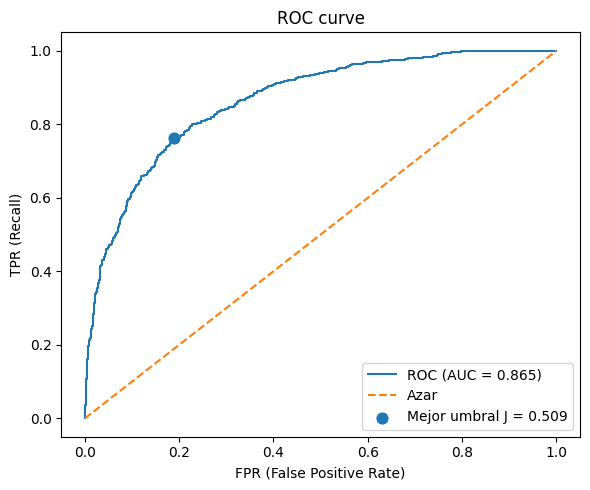

In [138]:
# --- 2) ROC ---
y_test_bin = (y_test == "positivo").astype(int)

# Calcula ROC y AUC
fpr, tpr, thr_roc = roc_curve(y_test_bin, y_proba_tfid)  # guarda thresholds
auc_roc = roc_auc_score(y_test_bin, y_proba_tfid)

# (A) Mejor umbral por Youden's J = TPR - FPR
youden = tpr - fpr
idx_j = np.argmax(youden)
thr_j = thr_roc[idx_j]
fpr_j, tpr_j = fpr[idx_j], tpr[idx_j]

# (B) (Opcional) Menor distancia a (0,1)
dist = np.sqrt((fpr - 0)**2 + (tpr - 1)**2)
idx_d = np.argmin(dist)
thr_d = thr_roc[idx_d]
fpr_d, tpr_d = fpr[idx_d], tpr[idx_d]

# (C) (Opcional) Mejor F1 en curva PR (útil si la positiva es rara)
prec, rec, thr_pr = precision_recall_curve(y_test_bin, y_proba_tfid)
f1s = 2 * (prec * rec) / (prec + rec + 1e-12)
idx_f1 = np.nanargmax(f1s[:-1])  # el último punto no tiene umbral
thr_f1 = thr_pr[idx_f1]

print(f"Umbral (Youden J): {thr_j:.4f}")
print(f"Umbral (Dist. a (0,1) mínima): {thr_d:.4f}")
print(f"Umbral (mejor F1 en PR): {thr_f1:.4f}")

# --- Plot ROC con el punto del mejor umbral (Youden J) ---
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f"ROC (AUC = {auc_roc:.3f})")
plt.plot([0,1], [0,1], linestyle="--", label="Azar")

# Marca el mejor punto (Youden J)
plt.scatter([fpr_j], [tpr_j], s=60, marker='o',
            label=f"Mejor umbral J = {thr_j:.3f}")

# (Opcional) marca el de mínima distancia
# plt.scatter([fpr_d], [tpr_d], s=60, marker='s',
#             label=f"Min dist (thr={thr_d:.3f})")

plt.xlabel("FPR (False Positive Rate)")
plt.ylabel("TPR (Recall)")
plt.title("ROC curve")
plt.legend()
plt.tight_layout()
plt.show()

Mejor umbral (F1 máx): 0.4824
Precision=0.736  Recall=0.800  F1=0.767
Average Precision (AP): 0.833


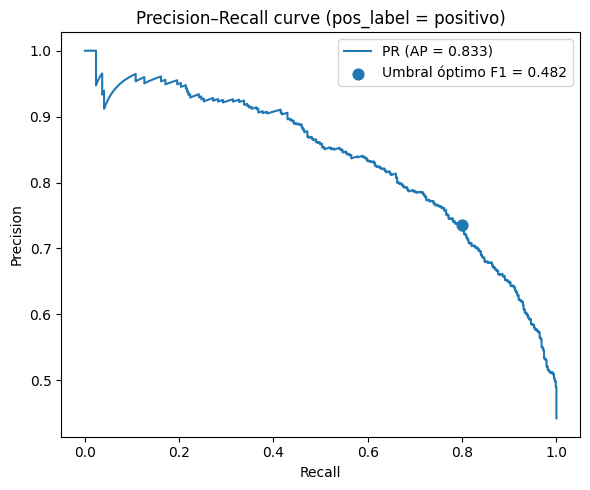

In [139]:
pos_label = logreg_count.classes_[1]

# Curva PR (nota: len(thr_pr) = len(prec) - 1)
prec, rec, thr_pr = precision_recall_curve(y_test_bin, y_proba_tfid)
ap = average_precision_score(y_test_bin, y_proba_tfid)

# F1 en cada punto de la curva (el último punto no tiene umbral)
f1s = 2 * (prec * rec) / (prec + rec + 1e-12)
best_idx = np.nanargmax(f1s[:-1])      # evitar el último punto sin umbral
best_thr = thr_pr[best_idx]
best_prec = prec[best_idx]
best_rec = rec[best_idx]
best_f1 = f1s[best_idx]

print(f"Mejor umbral (F1 máx): {best_thr:.4f}")
print(f"Precision={best_prec:.3f}  Recall={best_rec:.3f}  F1={best_f1:.3f}")
print(f"Average Precision (AP): {ap:.3f}")

# Predicciones con el mejor umbral (si quieres usarlas)
y_pred_best = (y_proba_tfid >= best_thr).astype(int)

# --- Plot PR con el punto óptimo ---
plt.figure(figsize=(6,5))
plt.plot(rec, prec, label=f"PR (AP = {ap:.3f})")
plt.scatter([best_rec], [best_prec], s=60, marker='o',
            label=f"Umbral óptimo F1 = {best_thr:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(f"Precision–Recall curve (pos_label = {pos_label})")
plt.legend()
plt.tight_layout()
plt.show()

In [140]:
# --- 1) Usa el umbral óptimo que ya calculaste ---
thr_opt = best_thr   # p.ej., el que maximizó F1 en la curva PR

# --- 2) Probabilidades para la clase positiva ---
pos_label = logreg.classes_[1]
neg_label = logreg.classes_[0]
pos_idx = list(logreg.classes_).index(pos_label)

# Si tu test es BoW:
y_proba_tfid = logreg.predict_proba(X_test_bow_tfid)[:, pos_idx]
# (si usas TF-IDF, cambia X_test_bow por X_test_tfidf o reutiliza y_proba_tfid)

# --- 3) Predicción con umbral custom ---
y_pred_thr = np.where(y_proba_tfid >= thr_opt, pos_label, neg_label)

# --- 4) Métricas con el nuevo umbral ---
print("Accuracy:", accuracy_score(y_test, y_pred_thr))
print("\nClassification report (umbral óptimo):\n",
      classification_report(y_test, y_pred_thr))

Accuracy: 0.7844276583381755

Classification report (umbral óptimo):
                  precision    recall  f1-score   support

negativo-neutro       0.83      0.77      0.80       960
       positivo       0.74      0.80      0.77       761

       accuracy                           0.78      1721
      macro avg       0.78      0.79      0.78      1721
   weighted avg       0.79      0.78      0.79      1721



# 🎯 Lo esencial que logramos

- **Limpieza robusta:** Normalizamos texto sin romper caracteres en español (tildes y ñ), evitando que la puntuación “pegue” palabras.
- **Lematización en español (spaCy):** Transformamos a formas base y filtramos stopwords antes de vectorizar; reduce ruido y variantes verbales.
- **Tokenización práctica:** Evitamos dependencias innecesarias de NLTK en producción usando `tokenizer=str.split` (y, si se usa NLTK, resolvimos el error de punkt/punkt_tab).
- **Vectorización:**
  - `CountVectorizer` = BoW interpretable (conteos), útil para exploración y Naive Bayes.
  - `TfidfVectorizer` = pesos informativos (↓ términos muy comunes), baseline fuerte para LogReg/SVM y búsqueda por similitud.
  - **N-gramas:** `(1,2)` captura contexto corto sin disparar demasiado el vocabulario; character n-grams útiles ante typos.
- **Evaluación completa:** Métricas clásicas (Accuracy, Precision, Recall, F1) + curvas ROC y PR con sus áreas (AUC-ROC, AP/AUC-PR), y ajuste de umbral según costo de errores.
- **Visual & doc:** Matriz de confusión Positive/Negative, guía para citar fuentes en imágenes, y gráficos de importancia de términos.

---

# ✅ Buenas prácticas implementadas

- **Sin fuga de información:** Fit del vectorizador solo en train, transform en test.
- **Consistencia del pipeline:** Si ya lematizas/minusculizas/separas por espacio, usa  
  `tokenizer=str.split`, `preprocessor=None`, `lowercase=False`, `token_pattern=None`.
- **Control del vocabulario:** `min_df`, `max_df`, `ngram_range`, `max_features` para evitar modelos enormes e inestables.
- **Probabilidades y umbral:** Reporta métricas por defecto (umbral 0.5) y también una versión optimizada (p. ej., mejor F1).
- **Desbalance:** No confiar solo en Accuracy; mirar F1, PR curve y Average Precision (AP).

---

# 📌 Recomendaciones operativas (checklist)

- **Preproc:** Mantener acentos para lematizar y (si se requiere) retirarlos al final sin perder la ñ.
- **spaCy:** Para muchos textos, usar `nlp.pipe(batch_size, n_process)` y cachear `stop_words`.
- **Features (baseline):** `TfidfVectorizer(sublinear_tf=True, ngram_range=(1,2), min_df=3)`.
- **Modelo (baseline):** `LogisticRegression(C=1.0~4.0, max_iter=2000, class_weight='balanced')`.
- **CV:** `StratifiedKFold` + `scoring='f1_macro'` (o `average_precision` si la positiva es rara).
- **Interpretabilidad:** Revisar top coeficientes por clase; detectar fugas semánticas (términos de etiqueta).
- **Documentación:** Incluir fuentes y dejar claro cuál es la clase positiva en cada gráfico.

---

# 🔭 Siguientes pasos sugeridos

- **Búsqueda de hiperparámetros:** `C`, `min_df`, `max_df`, `ngram_range`, `max_features`.
- **Calibración de probabilidades:** `CalibratedClassifierCV` si vas a decidir por umbral.
- **Error analysis:** Inspeccionar FP/FN con ejemplos de texto; crear reglas/lexicones de dominio si aplica.
- **Robustez:** Comparar BoW/TF-IDF con embeddings (p. ej., fastText / Sentence-BERT) como extensión avanzada.

---

# 🧪 Fórmulas clave (LaTeX)

- **Precision:**  
  $ \displaystyle \mathrm{Precision}=\frac{TP}{TP+FP} $
- **Recall:**  
  $ \displaystyle \mathrm{Recall}=\frac{TP}{TP+FN} $
- **F1:**  
  $ \displaystyle \mathrm{F1}=2\cdot\frac{\mathrm{Precision}\cdot\mathrm{Recall}}{\mathrm{Precision}+\mathrm{Recall}} $
- **Regla de decisión por umbral:**  
  $ \displaystyle \hat{y}=\mathbb{1},[\hat{p}(y{=}1\mid x)\ge \tau] $
- **AUC-PR (AP):**  
  Área bajo la curva Precision–Recall (promedio de precisión